# Student Academic Risk Prediction
## Sistem Prediksi dan Analisis Risiko Akademik Siswa — Multilayer Perceptron (DNN)
Pipeline: Setup → Load Data → EDA → Preprocessing → Model MLP → Training → Evaluasi → Skenario → Fitur Unik (Focal Loss & Integrated Gradients) → Simpan Artefak → Ekspor Proyek → Aplikasi Web (Gradio)

## 0. Setup

In [1]:
# Colab sudah menyediakan TensorFlow; cukup pasang Gradio & kagglehub
!pip -q install gradio kagglehub

In [2]:
import os, sys, json, glob, zipfile, io, random, warnings, platform, shutil, urllib.request
warnings.filterwarnings("ignore")
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
import sklearn, joblib
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             classification_report, roc_curve, precision_recall_curve)

SEED = 42
def set_seed(seed=SEED):
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed); np.random.seed(seed)
    keras.utils.set_random_seed(seed)
tf.config.experimental.enable_op_determinism()
set_seed()

sns.set_theme(style="whitegrid", context="notebook")
C_SAFE, C_RISK = "#2E86AB", "#E4572E"
PALETTE = {0: C_SAFE, 1: C_RISK}

VERSIONS = {
    "python": platform.python_version(), "tensorflow": tf.__version__, "keras": keras.__version__,
    "numpy": np.__version__, "pandas": pd.__version__, "scikit-learn": sklearn.__version__,
    "matplotlib": matplotlib.__version__, "seaborn": sns.__version__,
}
try:
    import gradio as gr; VERSIONS["gradio"] = gr.__version__
except Exception:
    VERSIONS["gradio"] = "not installed"
VERSIONS["gpu"] = [d.name for d in tf.config.list_physical_devices("GPU")] or "CPU only"
for k, v in VERSIONS.items(): print(f"{k:13s}: {v}")

I0000 00:00:1793991737.122753     265 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1793991737.920373     265 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


python       : 3.13.18
tensorflow   : 2.21.0
keras        : 3.15.1
numpy        : 2.5.3
pandas       : 3.0.5
scikit-learn : 1.9.1
matplotlib   : 3.11.2
seaborn      : 0.13.2
gradio       : 6.31.0
gpu          : CPU only


In [3]:
# Struktur proyek (semua output disimpan di folder ini lalu di-zip untuk GitHub)
PROJECT_DIR = "student-academic-risk"
if os.path.basename(os.getcwd()) != PROJECT_DIR:
    os.makedirs(PROJECT_DIR, exist_ok=True)
    os.chdir(PROJECT_DIR)
for d in ["data", "models", "results", "figures"]:
    os.makedirs(d, exist_ok=True)
print("Working dir:", os.getcwd())

def savefig(name):
    plt.tight_layout()
    plt.savefig(f"figures/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

Working dir: /home/claude/run/student-academic-risk


## 1. Load Dataset
Sumber: https://www.kaggle.com/datasets/larsen0966/student-performance-data-set (file `student-por.csv`)

In [4]:
DATA_PATH = "data/student-por.csv"
KAGGLE_ID = "larsen0966/student-performance-data-set"
UCI_ZIP = "https://archive.ics.uci.edu/static/public/320/student+performance.zip"

def fetch_dataset():
    if os.path.exists(DATA_PATH):
        return "local"
    try:  # 1) Kaggle (kagglehub)
        import kagglehub
        path = kagglehub.dataset_download(KAGGLE_ID)
        cand = [p for p in glob.glob(os.path.join(path, "**", "*.csv"), recursive=True) if "por" in os.path.basename(p).lower()]
        shutil.copy(cand[0], DATA_PATH)
        return "kaggle"
    except Exception as e:
        print("Kaggle gagal:", e)
    # 2) Mirror UCI (dataset asli yang sama)
    raw = urllib.request.urlopen(UCI_ZIP, timeout=60).read()
    z = zipfile.ZipFile(io.BytesIO(raw))
    inner = zipfile.ZipFile(io.BytesIO(z.read("student.zip"))) if "student.zip" in z.namelist() else z
    with open(DATA_PATH, "wb") as f:
        f.write(inner.read("student-por.csv"))
    return "uci"

print("Sumber data:", fetch_dataset())
df_raw = pd.read_csv(DATA_PATH, sep=None, engine="python")   # deteksi otomatis ';' atau ','
df_raw.columns = [c.strip().strip('"') for c in df_raw.columns]
print("Shape:", df_raw.shape)
df_raw.head()

Sumber data: local
Shape: (649, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13


## 2. Exploratory Data Analysis (EDA)

In [5]:
TARGET_GRADE = "G3"
PASS_MARK = 10          # skala Portugal 0-20; < 10 = tidak lulus
BINARY_COLS  = ["school", "sex", "address", "famsize", "Pstatus", "schoolsup", "famsup", "paid",
                "activities", "nursery", "higher", "internet", "romantic"]
NOMINAL_COLS = ["Mjob", "Fjob", "reason", "guardian"]
NUMERIC_COLS = ["age", "Medu", "Fedu", "traveltime", "studytime", "failures", "famrel", "freetime",
                "goout", "Dalc", "Walc", "health", "absences", "G1", "G2"]
FEATURES = NUMERIC_COLS + BINARY_COLS + NOMINAL_COLS

df_raw.info()
print("\nMissing values total:", int(df_raw.isna().sum().sum()))
print("Baris duplikat     :", int(df_raw.duplicated().sum()))
df_raw.describe().T.round(2)

<class 'pandas.DataFrame'>
RangeIndex: 649 entries, 0 to 648
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   school      649 non-null    str  
 1   sex         649 non-null    str  
 2   age         649 non-null    int64
 3   address     649 non-null    str  
 4   famsize     649 non-null    str  
 5   Pstatus     649 non-null    str  
 6   Medu        649 non-null    int64
 7   Fedu        649 non-null    int64
 8   Mjob        649 non-null    str  
 9   Fjob        649 non-null    str  
 10  reason      649 non-null    str  
 11  guardian    649 non-null    str  
 12  traveltime  649 non-null    int64
 13  studytime   649 non-null    int64
 14  failures    649 non-null    int64
 15  schoolsup   649 non-null    str  
 16  famsup      649 non-null    str  
 17  paid        649 non-null    str  
 18  activities  649 non-null    str  
 19  nursery     649 non-null    str  
 20  higher      649 non-null    str  
 21  inte

,count,mean,std,min,25%,50%,75%,max
age,649.0,16.74,1.22,15.0,16.0,17.0,18.0,22.0
Medu,649.0,2.51,1.13,0.0,2.0,2.0,4.0,4.0
Fedu,649.0,2.31,1.10,0.0,1.0,2.0,3.0,4.0
traveltime,649.0,1.57,0.75,1.0,1.0,1.0,2.0,4.0
studytime,649.0,1.93,0.83,1.0,1.0,2.0,2.0,4.0
failures,649.0,0.22,0.59,0.0,0.0,0.0,0.0,3.0
famrel,649.0,3.93,0.96,1.0,4.0,4.0,5.0,5.0
freetime,649.0,3.18,1.05,1.0,3.0,3.0,4.0,5.0
goout,649.0,3.18,1.18,1.0,2.0,3.0,4.0,5.0
Dalc,649.0,1.50,0.92,1.0,1.0,1.0,2.0,5.0


                jumlah  persen
at_risk                       
Tidak Berisiko     549   84.59
Berisiko           100   15.41
Rasio imbalance (mayoritas:minoritas) = 5.49 : 1


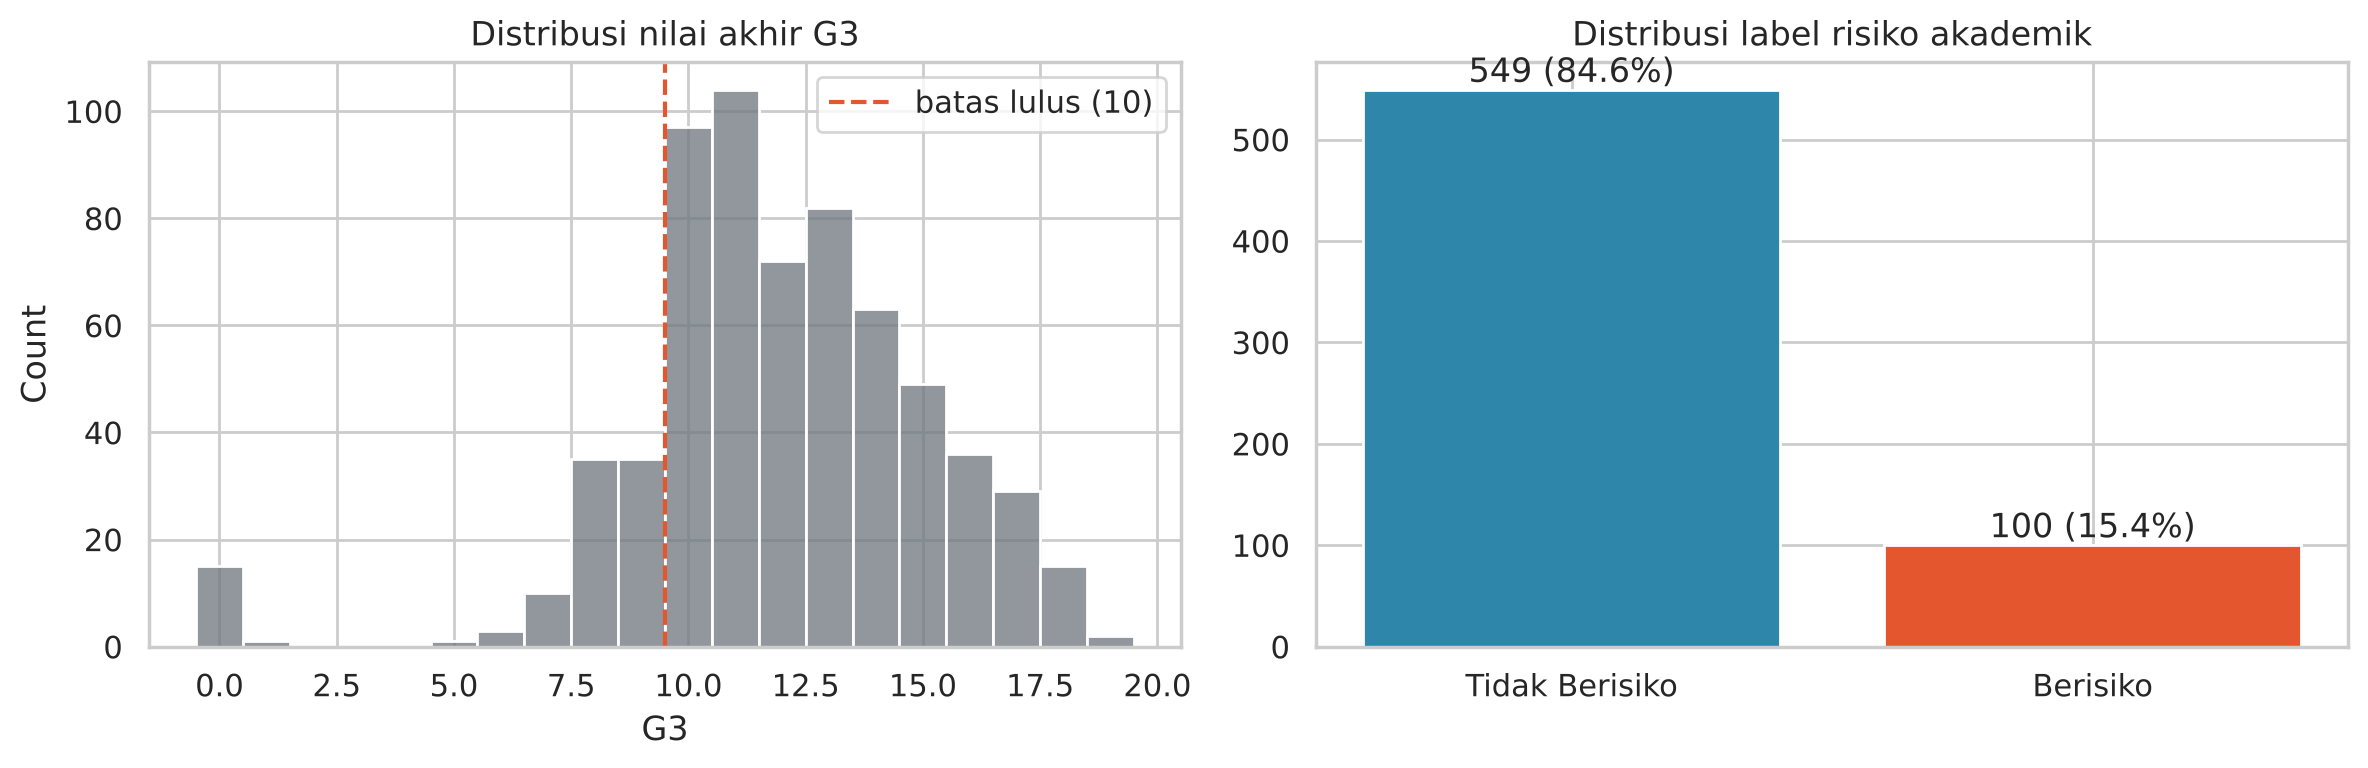

In [6]:
df = df_raw.copy()
for c in ["G1", "G2", "G3"]:
    df[c] = pd.to_numeric(df[c], errors="coerce")
df["at_risk"] = (df[TARGET_GRADE] < PASS_MARK).astype(int)
LABELS = {0: "Tidak Berisiko", 1: "Berisiko"}

counts = df["at_risk"].value_counts().sort_index()
print(pd.DataFrame({"jumlah": counts, "persen": (counts / len(df) * 100).round(2)}).rename(index=LABELS))
print("Rasio imbalance (mayoritas:minoritas) = %.2f : 1" % (counts[0] / counts[1]))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df[TARGET_GRADE], bins=21, discrete=True, ax=ax[0], color="#6C757D")
ax[0].axvline(PASS_MARK - 0.5, color=C_RISK, ls="--", label="batas lulus (10)")
ax[0].set_title("Distribusi nilai akhir G3"); ax[0].legend()
bars = ax[1].bar([LABELS[0], LABELS[1]], counts.values, color=[C_SAFE, C_RISK])
ax[1].bar_label(bars, labels=[f"{v} ({v/len(df)*100:.1f}%)" for v in counts.values])
ax[1].set_title("Distribusi label risiko akademik")
savefig("01_distribusi_label")

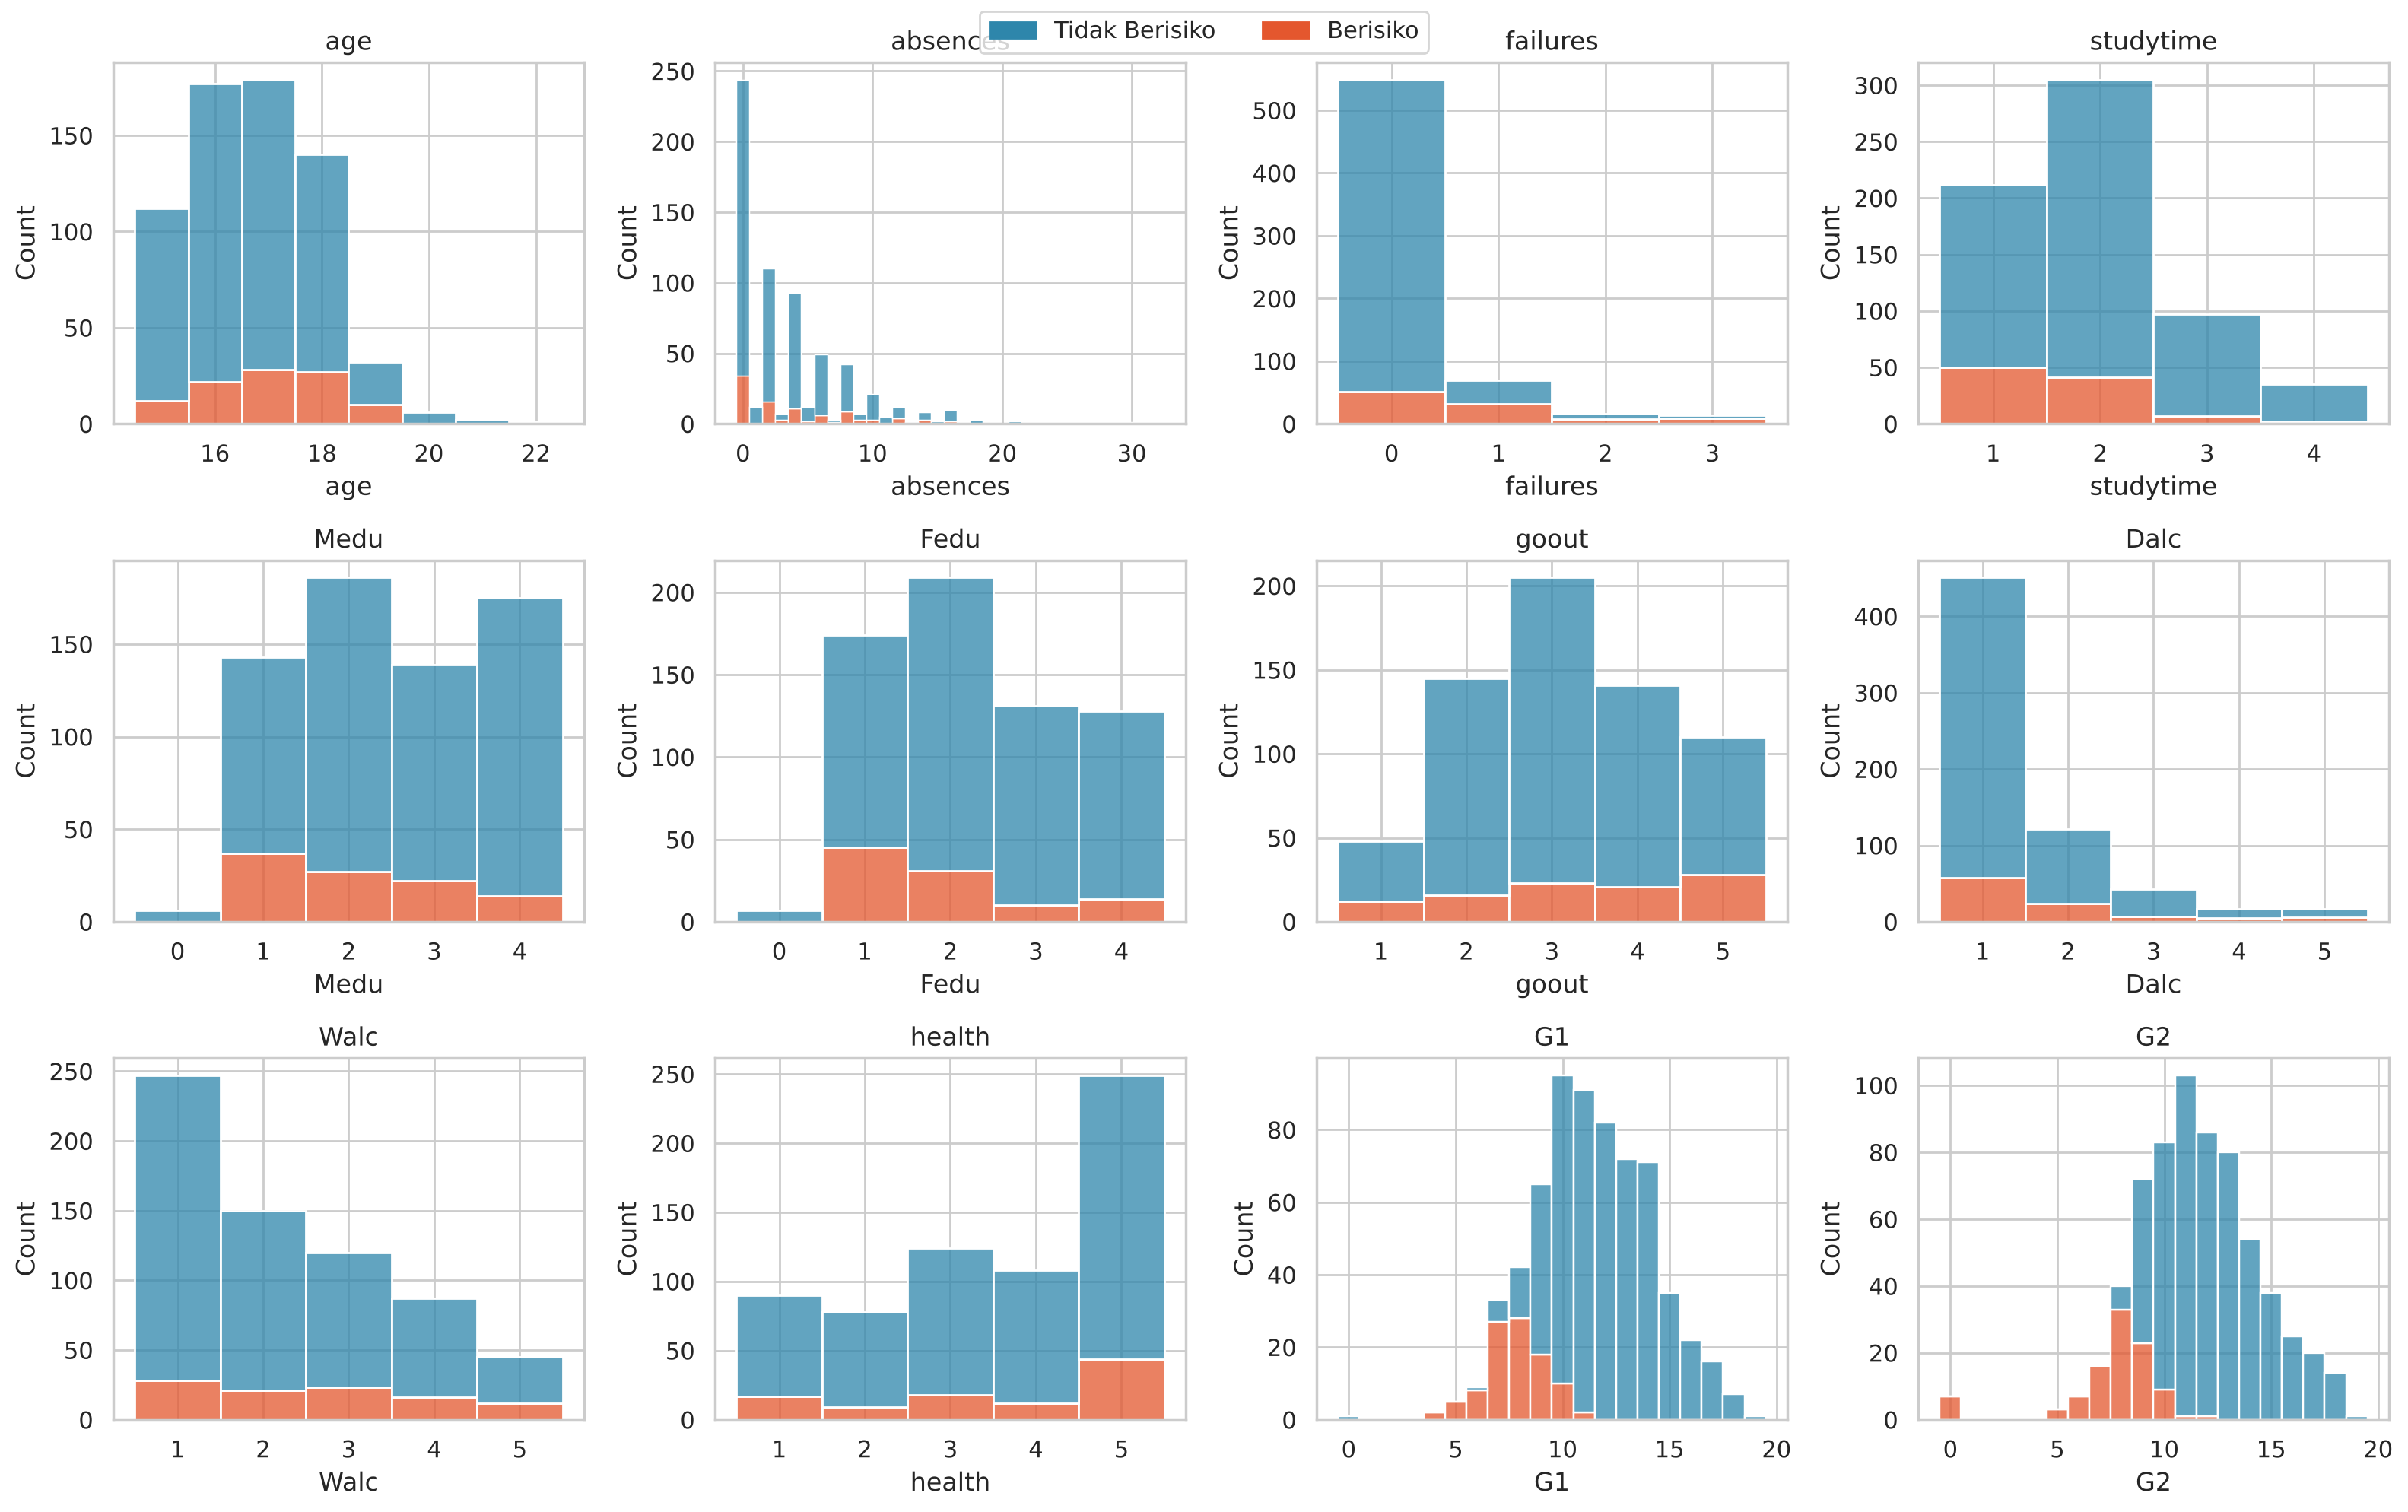

In [7]:
hist_cols = ["age", "absences", "failures", "studytime", "Medu", "Fedu", "goout", "Dalc", "Walc", "health", "G1", "G2"]
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, c in zip(axes.ravel(), hist_cols):
    sns.histplot(data=df, x=c, hue="at_risk", palette=PALETTE, multiple="stack", discrete=True, ax=ax, legend=False)
    ax.set_title(c)
fig.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=C_SAFE), plt.Rectangle((0, 0), 1, 1, color=C_RISK)],
           labels=[LABELS[0], LABELS[1]], loc="upper center", ncol=2)
plt.subplots_adjust(top=0.92)
savefig("02_histogram_fitur_numerik")

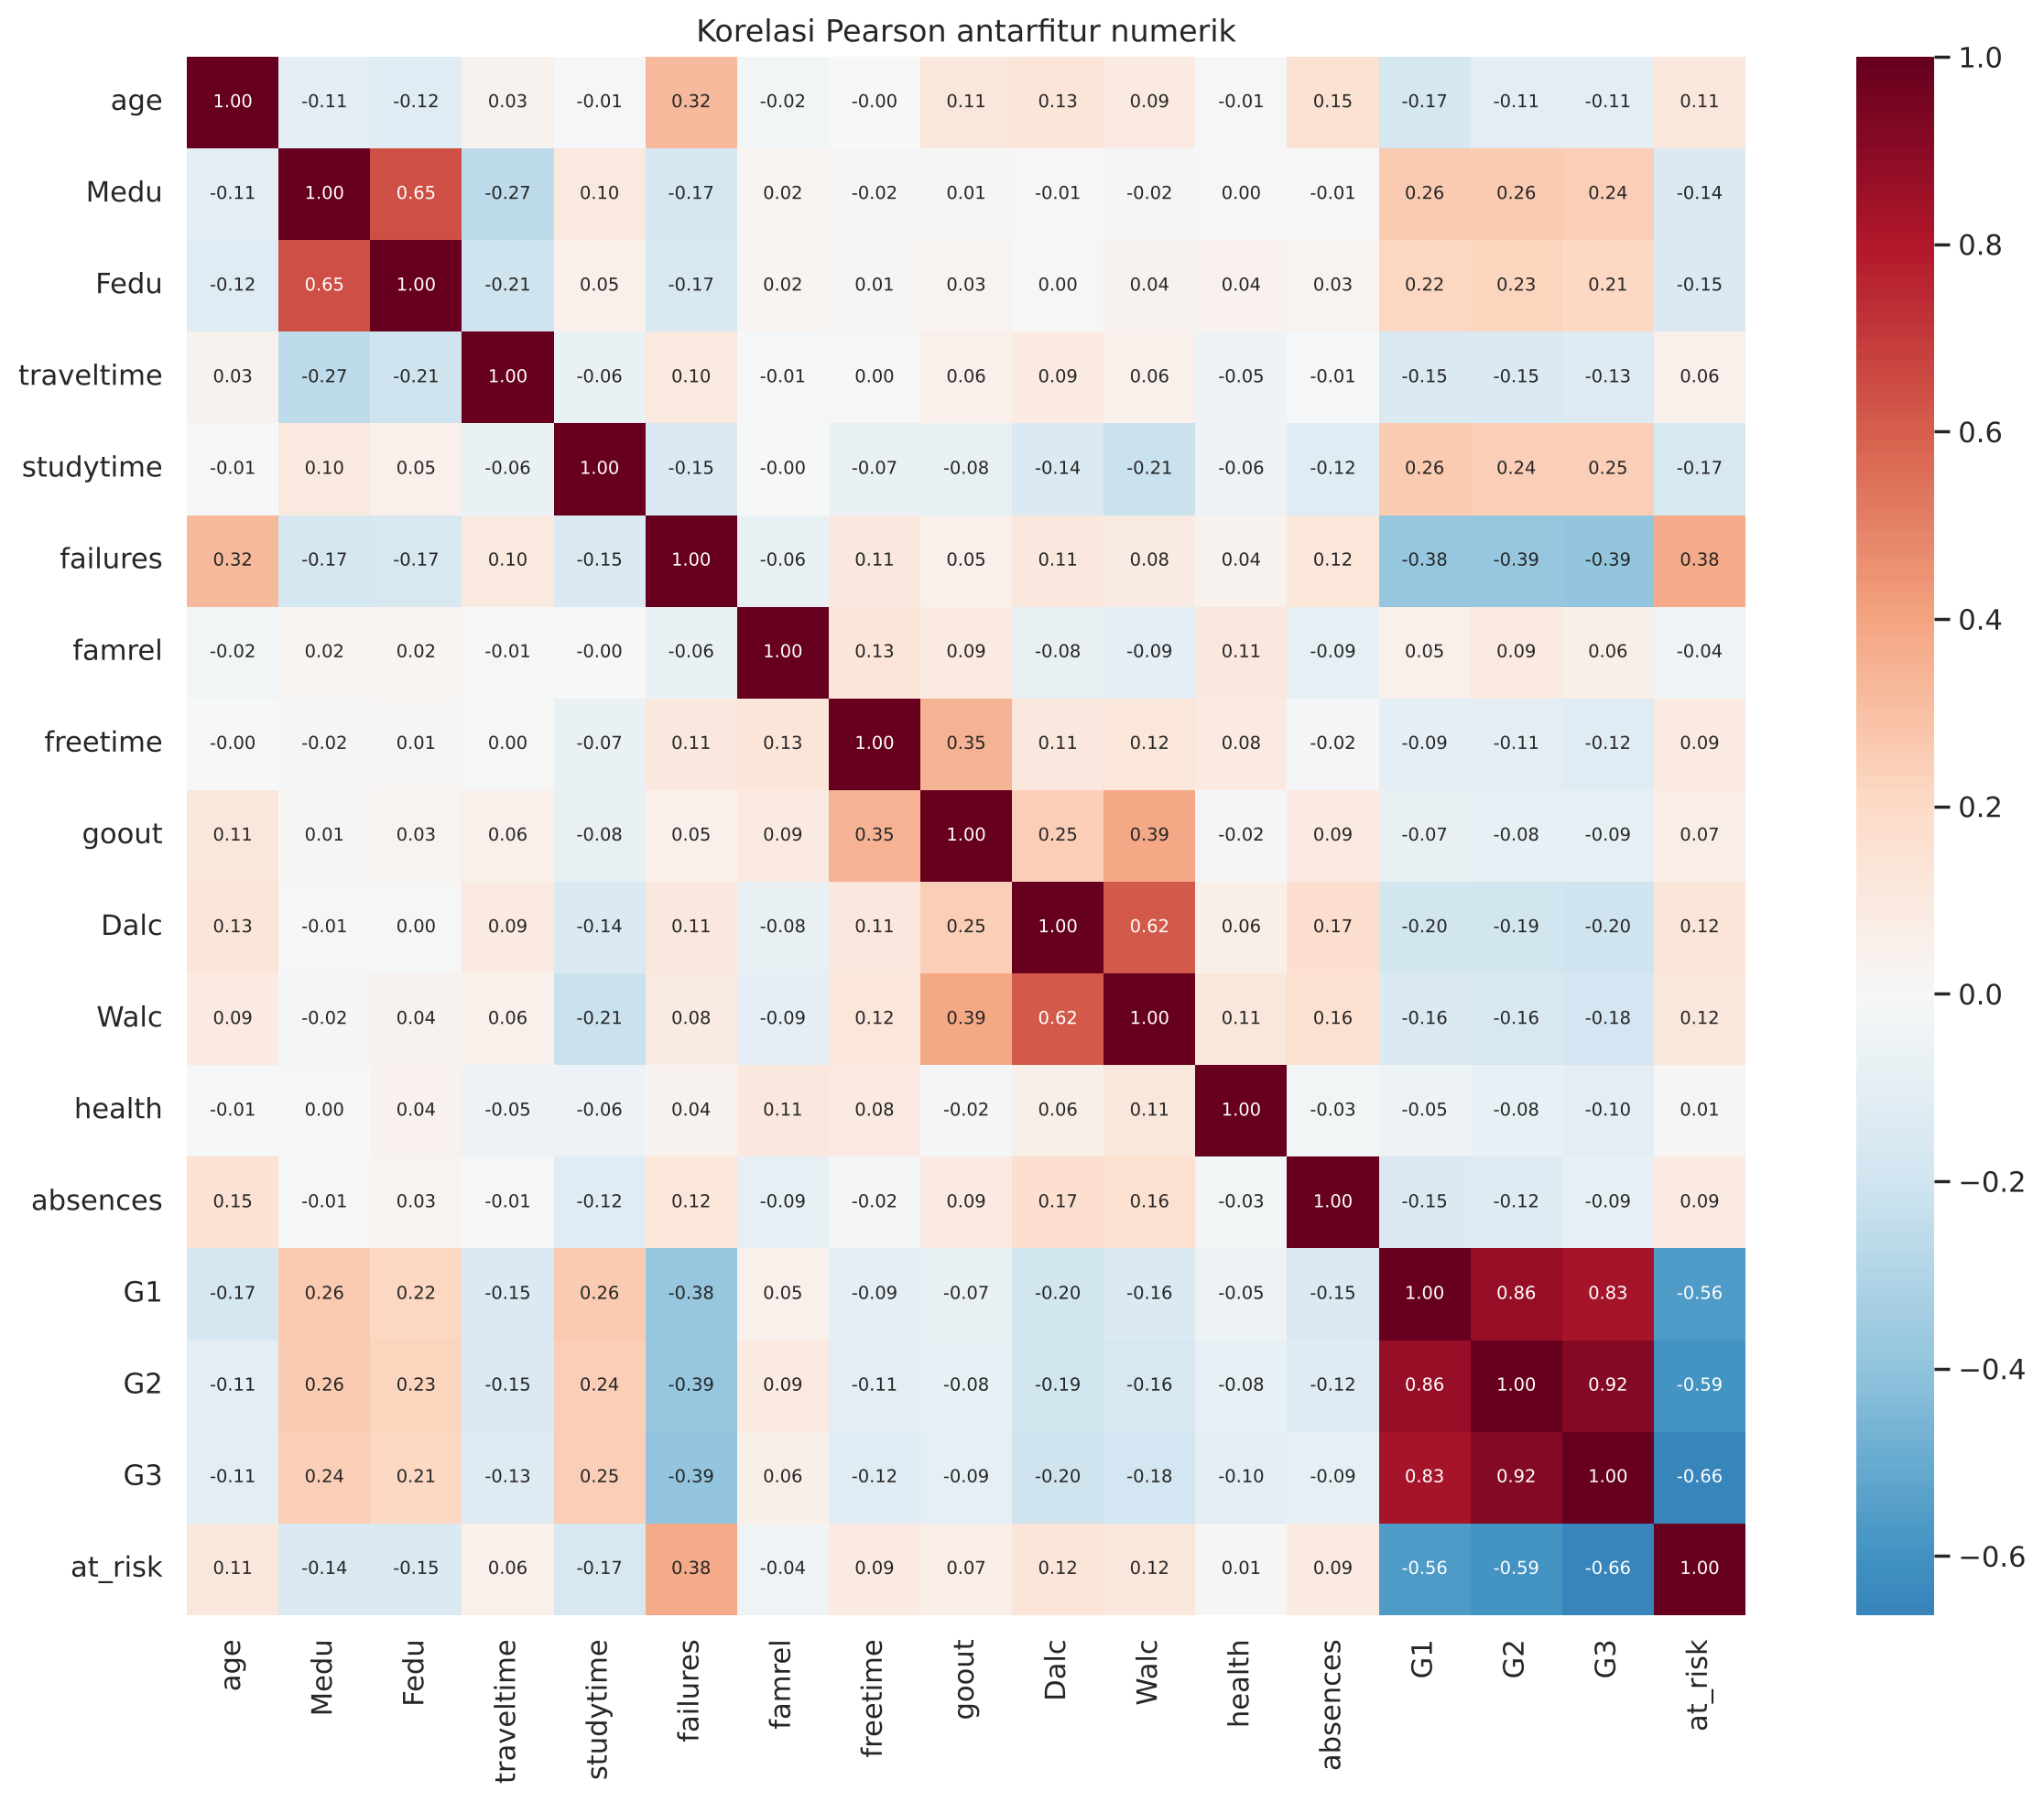

Korelasi terhadap at_risk (|r| terbesar):
G2          -0.592
G1          -0.563
failures     0.380
studytime   -0.165
Fedu        -0.146
Medu        -0.145
Dalc         0.124
Walc         0.116
age          0.111
freetime     0.093
Name: at_risk, dtype: float64


In [8]:
num_for_corr = NUMERIC_COLS + ["G3", "at_risk"]
corr = df[num_for_corr].corr()
plt.figure(figsize=(13, 10))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, annot_kws={"size": 7}, square=True)
plt.title("Korelasi Pearson antarfitur numerik")
savefig("03_korelasi_fitur")

corr_target = corr["at_risk"].drop(["at_risk", "G3"]).sort_values(key=abs, ascending=False)
print("Korelasi terhadap at_risk (|r| terbesar):"); print(corr_target.round(3).head(10))

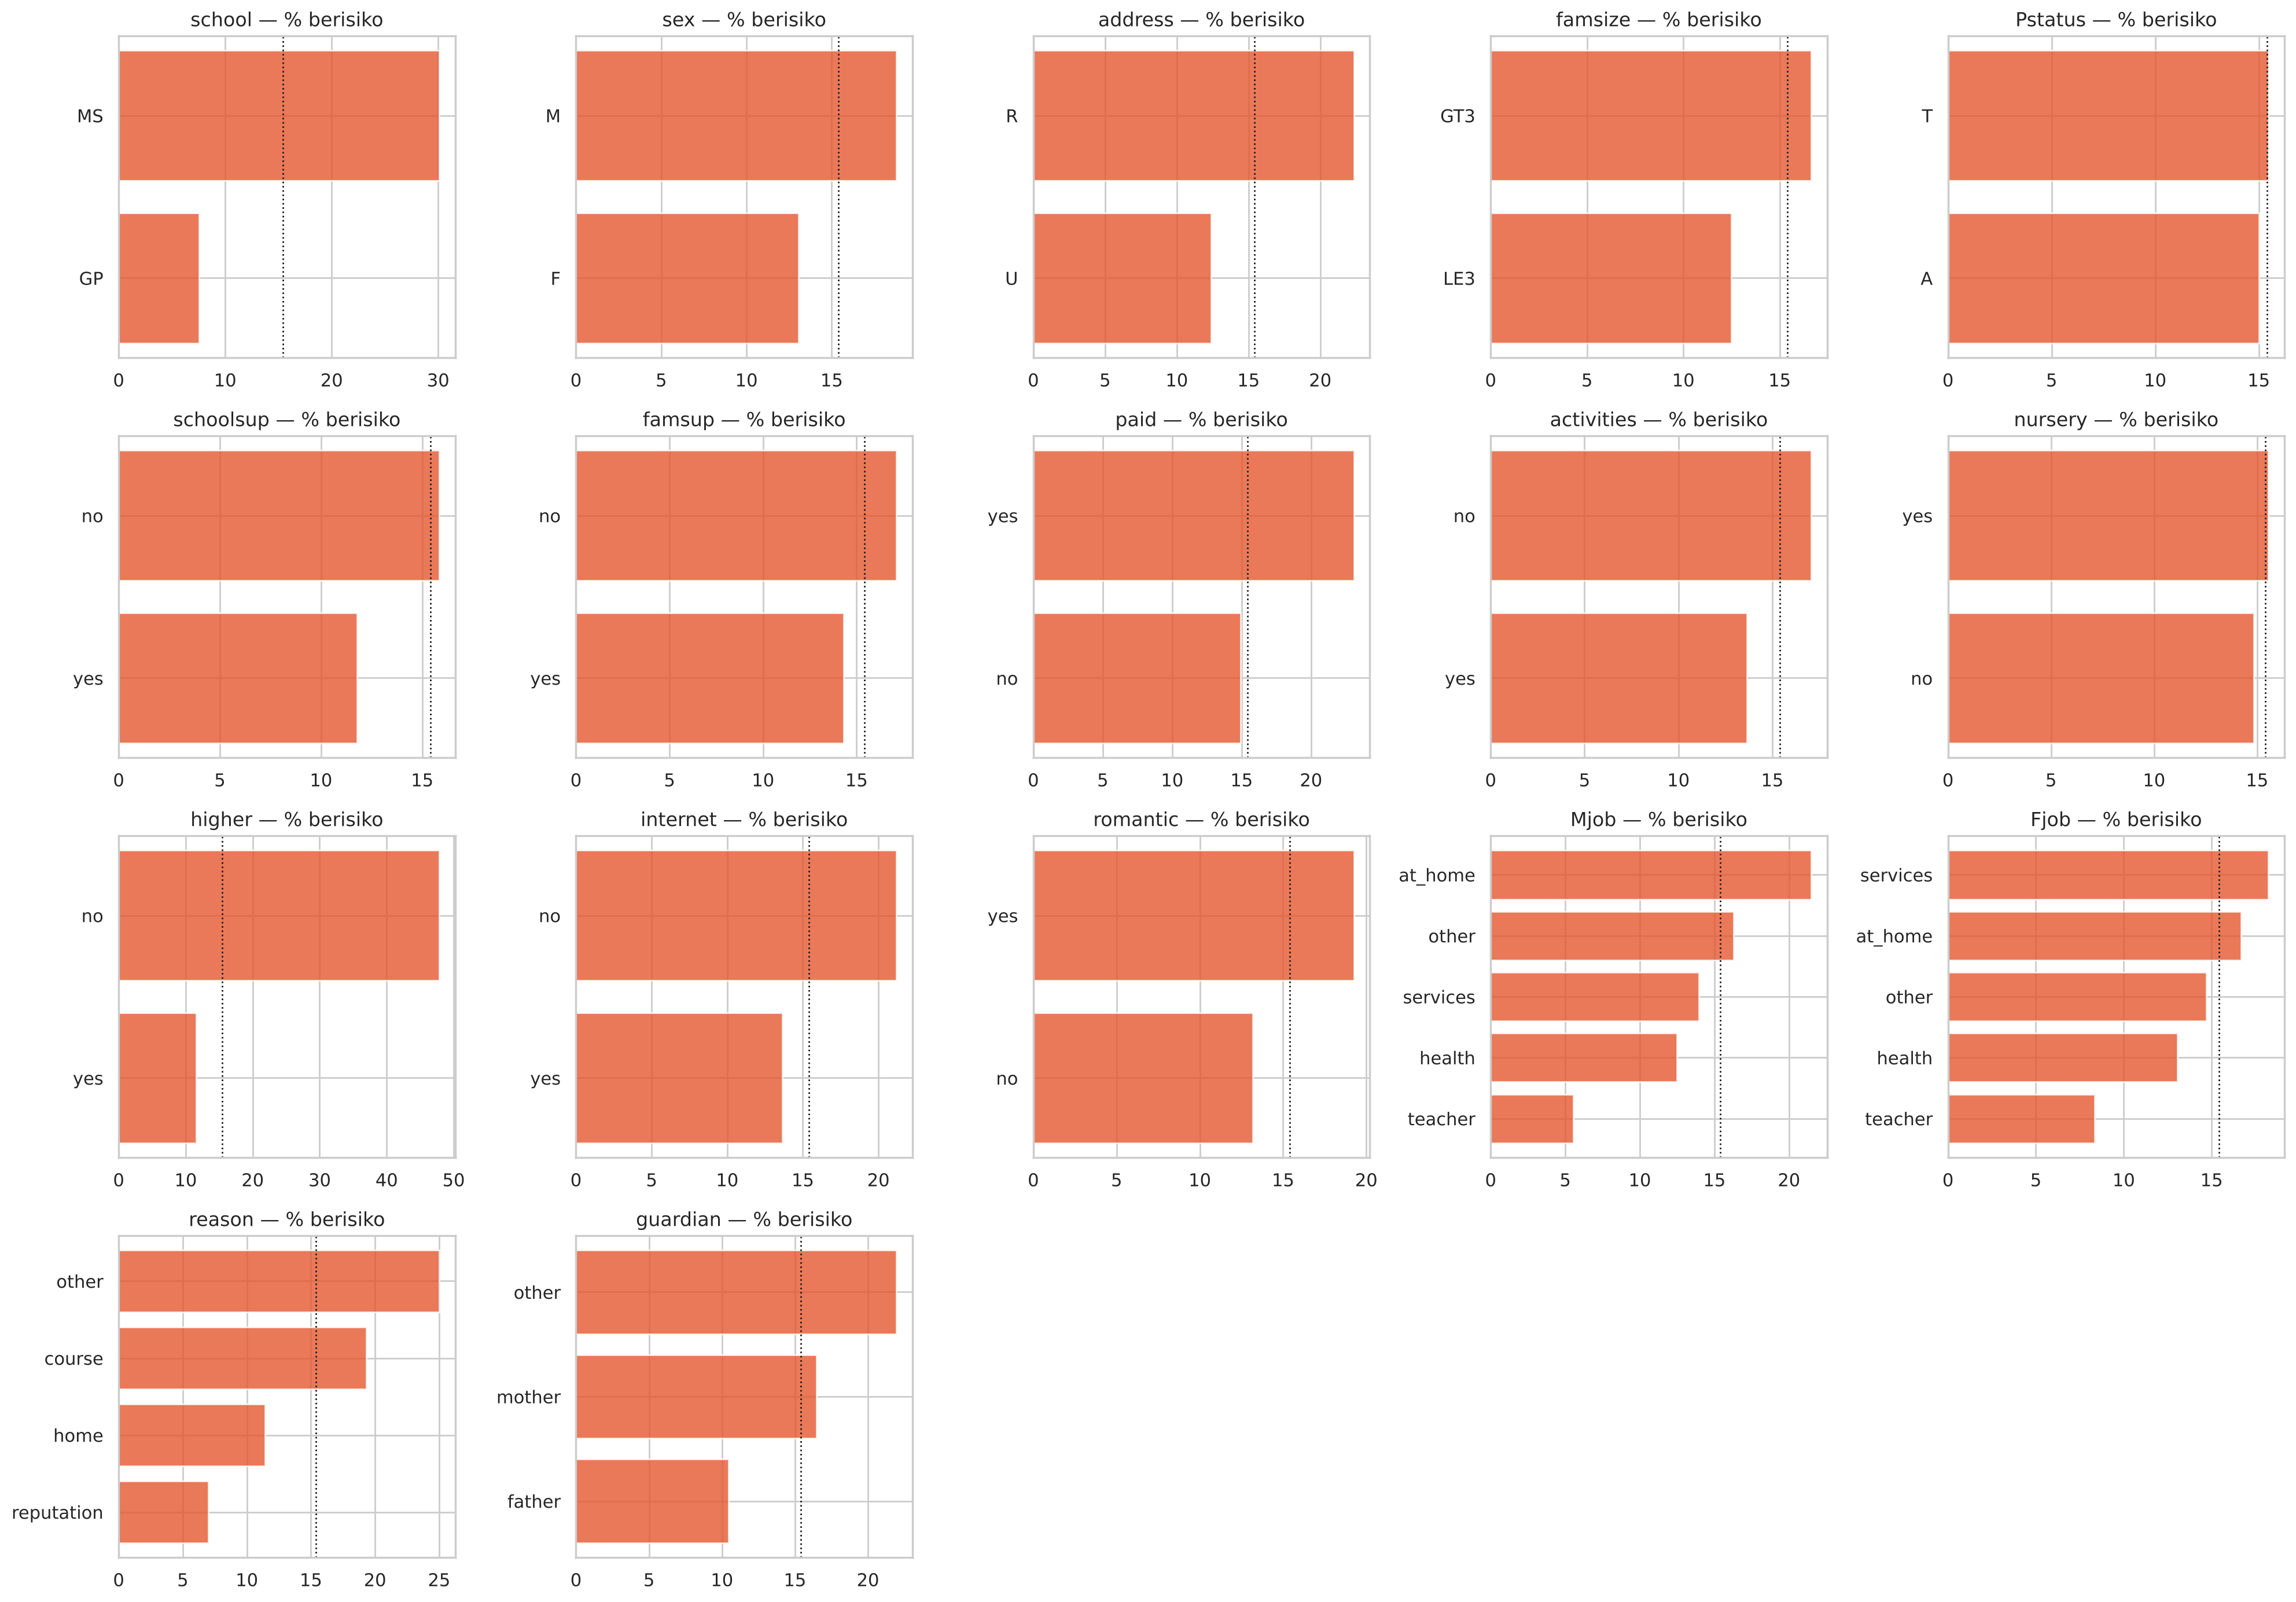

In [9]:
cat_cols = BINARY_COLS + NOMINAL_COLS
fig, axes = plt.subplots(4, 5, figsize=(20, 14))
for ax, c in zip(axes.ravel(), cat_cols):
    rate = df.groupby(c)["at_risk"].mean().sort_values() * 100
    ax.barh(rate.index.astype(str), rate.values, color=C_RISK, alpha=.8)
    ax.axvline(df["at_risk"].mean() * 100, color="k", ls=":", lw=1)
    ax.set_title(f"{c} — % berisiko")
for ax in axes.ravel()[len(cat_cols):]: ax.axis("off")
savefig("04_risk_rate_kategorikal")

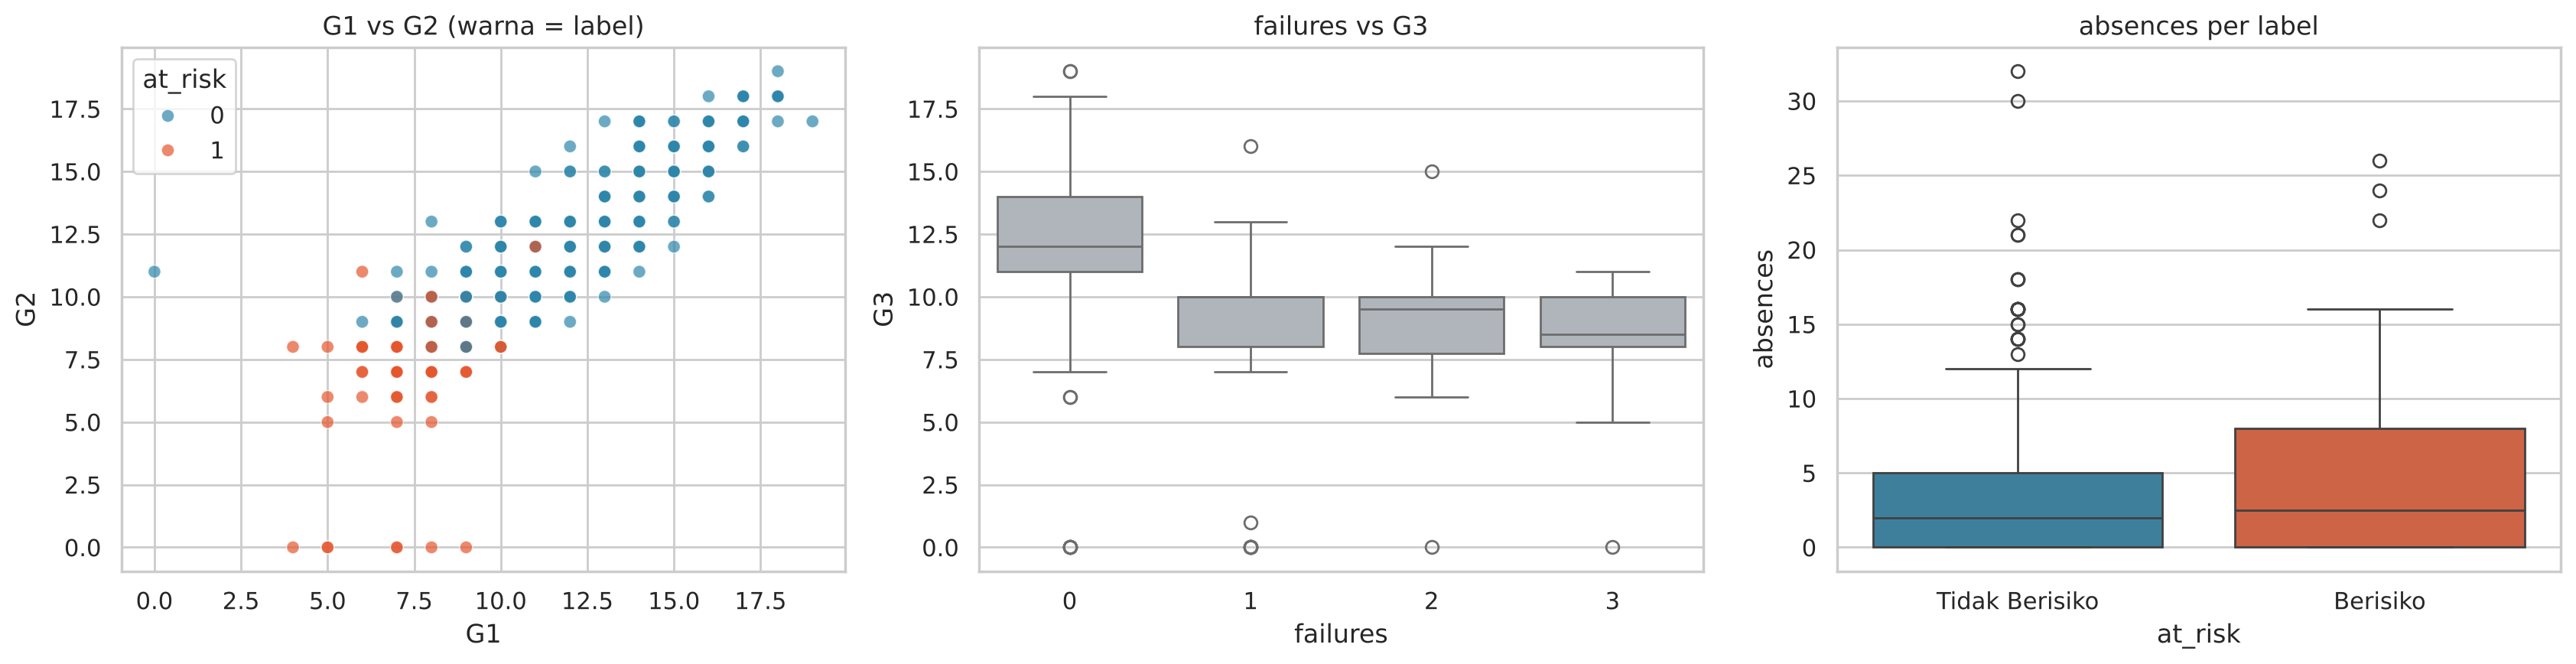

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
sns.scatterplot(data=df, x="G1", y="G2", hue="at_risk", palette=PALETTE, alpha=.7, ax=ax[0])
ax[0].set_title("G1 vs G2 (warna = label)")
sns.boxplot(data=df, x="failures", y="G3", ax=ax[1], color="#ADB5BD"); ax[1].set_title("failures vs G3")
sns.boxplot(data=df, x="at_risk", y="absences", hue="at_risk", palette=[C_SAFE, C_RISK], legend=False, ax=ax[2]); ax[2].set_xticks([0, 1]); ax[2].set_xticklabels([LABELS[0], LABELS[1]])
ax[2].set_title("absences per label")
savefig("05_hubungan_nilai_failures_absences")

In [11]:
# Contoh sampel data per kelas
for k in [0, 1]:
    print(f"=== {LABELS[k]} ===")
    display(df[df.at_risk == k].sample(5, random_state=SEED)[["school", "sex", "age", "studytime", "failures", "absences", "higher", "G1", "G2", "G3", "at_risk"]])

=== Tidak Berisiko ===


,school,sex,age,studytime,failures,absences,higher,G1,G2,G3,at_risk
213,GP,F,16,2,0,0,yes,11,10,11,0
82,GP,F,15,2,0,4,yes,12,11,11,0
547,MS,M,16,1,0,0,yes,10,11,11,0
113,GP,M,15,1,0,10,yes,18,17,18,0
539,MS,F,16,2,0,8,yes,9,10,10,0


=== Berisiko ===


,school,sex,age,studytime,failures,absences,higher,G1,G2,G3,at_risk
587,MS,F,18,2,1,3,yes,7,6,8,1
508,MS,M,17,1,1,0,yes,10,9,9,1
566,MS,M,18,1,1,2,no,9,7,9,1
478,MS,F,16,2,3,0,yes,7,7,8,1
476,MS,F,16,1,0,2,yes,10,8,8,1


In [12]:
# Ringkasan temuan EDA (dipakai untuk menentukan preprocessing)
q1, q3 = df["absences"].quantile([.25, .75]); iqr = q3 - q1
n_out_abs = int(((df["absences"] < q1 - 1.5 * iqr) | (df["absences"] > q3 + 1.5 * iqr)).sum())
EDA_SUMMARY = {
    "n_rows": int(len(df)), "n_cols_raw": int(df_raw.shape[1]),
    "n_features": len(FEATURES), "n_numeric": len(NUMERIC_COLS), "n_binary": len(BINARY_COLS), "n_nominal": len(NOMINAL_COLS),
    "n_at_risk": int(counts[1]), "n_not_at_risk": int(counts[0]),
    "pct_at_risk": round(float(counts[1] / len(df) * 100), 2), "imbalance_ratio": round(float(counts[0] / counts[1]), 2),
    "missing": int(df_raw.isna().sum().sum()), "duplicates": int(df_raw.duplicated().sum()),
    "g3_zero": int((df["G3"] == 0).sum()), "absences_outliers_iqr": n_out_abs, "absences_max": int(df["absences"].max()),
    "corr_at_risk_top": {k: round(float(v), 3) for k, v in corr_target.head(8).items()},
    "corr_G1_G2": round(float(corr.loc["G1", "G2"]), 3), "corr_G2_G3": round(float(corr.loc["G2", "G3"]), 3),
    "corr_G1_G3": round(float(corr.loc["G1", "G3"]), 3),
    "school_counts": df["school"].value_counts().to_dict(),
}
json.dump(EDA_SUMMARY, open("results/eda_summary.json", "w"), indent=2)
EDA_SUMMARY

{'n_rows': 649,
 'n_cols_raw': 33,
 'n_features': 32,
 'n_numeric': 15,
 'n_binary': 13,
 'n_nominal': 4,
 'n_at_risk': 100,
 'n_not_at_risk': 549,
 'pct_at_risk': 15.41,
 'imbalance_ratio': 5.49,
 'missing': 0,
 'duplicates': 0,
 'g3_zero': 15,
 'absences_outliers_iqr': 21,
 'absences_max': 32,
 'corr_at_risk_top': {'G2': -0.592,
  'G1': -0.563,
  'failures': 0.38,
  'studytime': -0.165,
  'Fedu': -0.146,
  'Medu': -0.145,
  'Dalc': 0.124,
  'Walc': 0.116},
 'corr_G1_G2': 0.865,
 'corr_G2_G3': 0.919,
 'corr_G1_G3': 0.826,
 'school_counts': {'GP': 423, 'MS': 226}}

## 3. Preprocessing
### Tahap 3.1 — Pemeriksaan & konversi tipe data

In [13]:
PREP = {}   # semua hasil preprocessing disimpan untuk laporan
dtype_tbl = pd.DataFrame({
    "dtype_awal": df_raw.dtypes.astype(str),
    "dtype_setelah": df.drop(columns="at_risk").dtypes.astype(str),
    "n_unik": df_raw.nunique(),
    "contoh": df_raw.iloc[0].astype(str),
})
dtype_tbl["kelompok"] = ["numerik" if c in NUMERIC_COLS + ["G3"] else "biner" if c in BINARY_COLS else "nominal" for c in dtype_tbl.index]
display(dtype_tbl)
nan_after_cast = int(df[["G1", "G2", "G3"]].isna().sum().sum())
print("Nilai gagal dikonversi ke numerik pada G1/G2/G3:", nan_after_cast)
PREP["dtypes"] = {"n_int": int(df_raw.select_dtypes("number").shape[1]),
                  "n_text": int(df_raw.shape[1] - df_raw.select_dtypes("number").shape[1]), "nan_after_cast": nan_after_cast,
                  "table": dtype_tbl.reset_index().rename(columns={"index": "kolom"}).astype(str).to_dict("records")}

,dtype_awal,dtype_setelah,n_unik,contoh,kelompok
school,str,str,2,GP,biner
sex,str,str,2,F,biner
age,int64,int64,8,18,numerik
address,str,str,2,U,biner
famsize,str,str,2,GT3,biner
Pstatus,str,str,2,A,biner
Medu,int64,int64,5,4,numerik
Fedu,int64,int64,5,4,numerik
Mjob,str,str,5,at_home,nominal
Fjob,str,str,5,teacher,nominal


Nilai gagal dikonversi ke numerik pada G1/G2/G3: 0


### Tahap 3.2 — Pemeriksaan missing value

In [14]:
miss = pd.DataFrame({"missing": df_raw.isna().sum(), "persen": (df_raw.isna().mean() * 100).round(2)})
print("Total missing value:", int(miss["missing"].sum()))
print("Kolom dengan missing > 0:", miss[miss.missing > 0].index.tolist() or "tidak ada")
display(miss.T)
PREP["missing_total"] = int(miss["missing"].sum())

Total missing value: 0
Kolom dengan missing > 0: tidak ada


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
missing,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
persen,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


### Tahap 3.3 — Pemeriksaan & penghapusan duplikat

In [15]:
n0 = len(df)
dup_full = int(df.duplicated().sum())
dup_feat = int(df.duplicated(subset=FEATURES).sum())               # fitur identik (label boleh beda)
dup_conflict = int(df[df.duplicated(subset=FEATURES, keep=False)].groupby(FEATURES)["at_risk"].nunique().gt(1).sum()) if dup_feat else 0
df = df.drop_duplicates().reset_index(drop=True)
print(f"Duplikat baris penuh: {dup_full} | duplikat berdasarkan fitur: {dup_feat} | duplikat dengan label bertentangan: {dup_conflict}")
print(f"Jumlah baris: {n0} -> {len(df)}")
PREP["duplicates"] = {"full": dup_full, "features_only": dup_feat, "conflicting_labels": dup_conflict, "rows_before": n0, "rows_after": len(df)}

Duplikat baris penuh: 0 | duplikat berdasarkan fitur: 0 | duplikat dengan label bertentangan: 0
Jumlah baris: 649 -> 649


### Tahap 3.4 — Validasi rentang nilai numerik (data rusak)

In [16]:
VALID_RANGES = {"age": (15, 22), "Medu": (0, 4), "Fedu": (0, 4), "traveltime": (1, 4), "studytime": (1, 4),
                "failures": (0, 3), "famrel": (1, 5), "freetime": (1, 5), "goout": (1, 5), "Dalc": (1, 5),
                "Walc": (1, 5), "health": (1, 5), "absences": (0, 93), "G1": (0, 20), "G2": (0, 20), "G3": (0, 20)}
rng_tbl = pd.DataFrame([{"kolom": c, "rentang_valid": f"{lo}-{hi}", "min": int(df[c].min()), "max": int(df[c].max()),
                         "n_tidak_valid": int((~df[c].between(lo, hi)).sum())} for c, (lo, hi) in VALID_RANGES.items()])
display(rng_tbl)
invalid = pd.Series(False, index=df.index)
for c, (lo, hi) in VALID_RANGES.items():
    invalid |= ~df[c].between(lo, hi)
invalid |= df[FEATURES + ["G3"]].isna().any(axis=1)
n1 = len(df)
df = df[~invalid].reset_index(drop=True)
print(f"Baris tidak valid dibuang: {int(invalid.sum())} | baris tersisa: {len(df)}")
PREP["range_check"] = rng_tbl.astype(str).to_dict("records"); PREP["invalid_rows"] = int(invalid.sum())
CLEAN = {"rows_before": n0, "rows_after": len(df), "removed_duplicates_or_invalid": n0 - len(df)}

,kolom,rentang_valid,min,max,n_tidak_valid
0,age,15-22,15,22,0
1,Medu,0-4,0,4,0
2,Fedu,0-4,0,4,0
3,traveltime,1-4,1,4,0
4,studytime,1-4,1,4,0
5,failures,0-3,0,3,0
6,famrel,1-5,1,5,0
7,freetime,1-5,1,5,0
8,goout,1-5,1,5,0
9,Dalc,1-5,1,5,0


Baris tidak valid dibuang: 0 | baris tersisa: 649


### Tahap 3.5 — Validasi nilai kategorikal (label/kategori salah)

In [17]:
EXPECTED_CATS = {"school": {"GP", "MS"}, "sex": {"F", "M"}, "address": {"U", "R"}, "famsize": {"LE3", "GT3"}, "Pstatus": {"T", "A"},
                 "Mjob": {"teacher", "health", "services", "at_home", "other"}, "Fjob": {"teacher", "health", "services", "at_home", "other"},
                 "reason": {"home", "reputation", "course", "other"}, "guardian": {"mother", "father", "other"},
                 **{c: {"yes", "no"} for c in ["schoolsup", "famsup", "paid", "activities", "nursery", "higher", "internet", "romantic"]}}
for c in BINARY_COLS + NOMINAL_COLS:
    df[c] = df[c].astype(str).str.strip().str.strip('"')         # rapikan spasi / tanda kutip
cat_tbl = pd.DataFrame([{"kolom": c, "kategori": ", ".join(f"{k}({v})" for k, v in df[c].value_counts().items()),
                         "tidak_dikenal": ", ".join(sorted(set(df[c].unique()) - EXPECTED_CATS[c])) or "-"} for c in BINARY_COLS + NOMINAL_COLS])
display(cat_tbl)
print("Total kategori tidak dikenal:", int(sum(len(set(df[c].unique()) - EXPECTED_CATS[c]) for c in EXPECTED_CATS)))
PREP["category_check"] = cat_tbl.to_dict("records")

,kolom,kategori,tidak_dikenal
0,school,"GP(423), MS(226)",-
1,sex,"F(383), M(266)",-
2,address,"U(452), R(197)",-
3,famsize,"GT3(457), LE3(192)",-
4,Pstatus,"T(569), A(80)",-
5,schoolsup,"no(581), yes(68)",-
6,famsup,"yes(398), no(251)",-
7,paid,"no(610), yes(39)",-
8,activities,"no(334), yes(315)",-
9,nursery,"yes(521), no(128)",-


Total kategori tidak dikenal: 0


### Tahap 3.6 — Deteksi outlier (IQR)

,kolom,Q1,Q3,IQR,batas_bawah,batas_atas,n_outlier,persen
0,age,16.0,18.0,2.0,13.0,21.0,1,0.15
1,Medu,2.0,4.0,2.0,-1.0,7.0,0,0.00
2,Fedu,1.0,3.0,2.0,-2.0,6.0,0,0.00
3,traveltime,1.0,2.0,1.0,-0.5,3.5,16,2.47
4,studytime,1.0,2.0,1.0,-0.5,3.5,35,5.39
5,failures,0.0,0.0,0.0,0.0,0.0,100,15.41
6,famrel,4.0,5.0,1.0,2.5,6.5,51,7.86
7,freetime,3.0,4.0,1.0,1.5,5.5,45,6.93
8,goout,2.0,4.0,2.0,-1.0,7.0,0,0.00
9,Dalc,1.0,2.0,1.0,-0.5,3.5,34,5.24


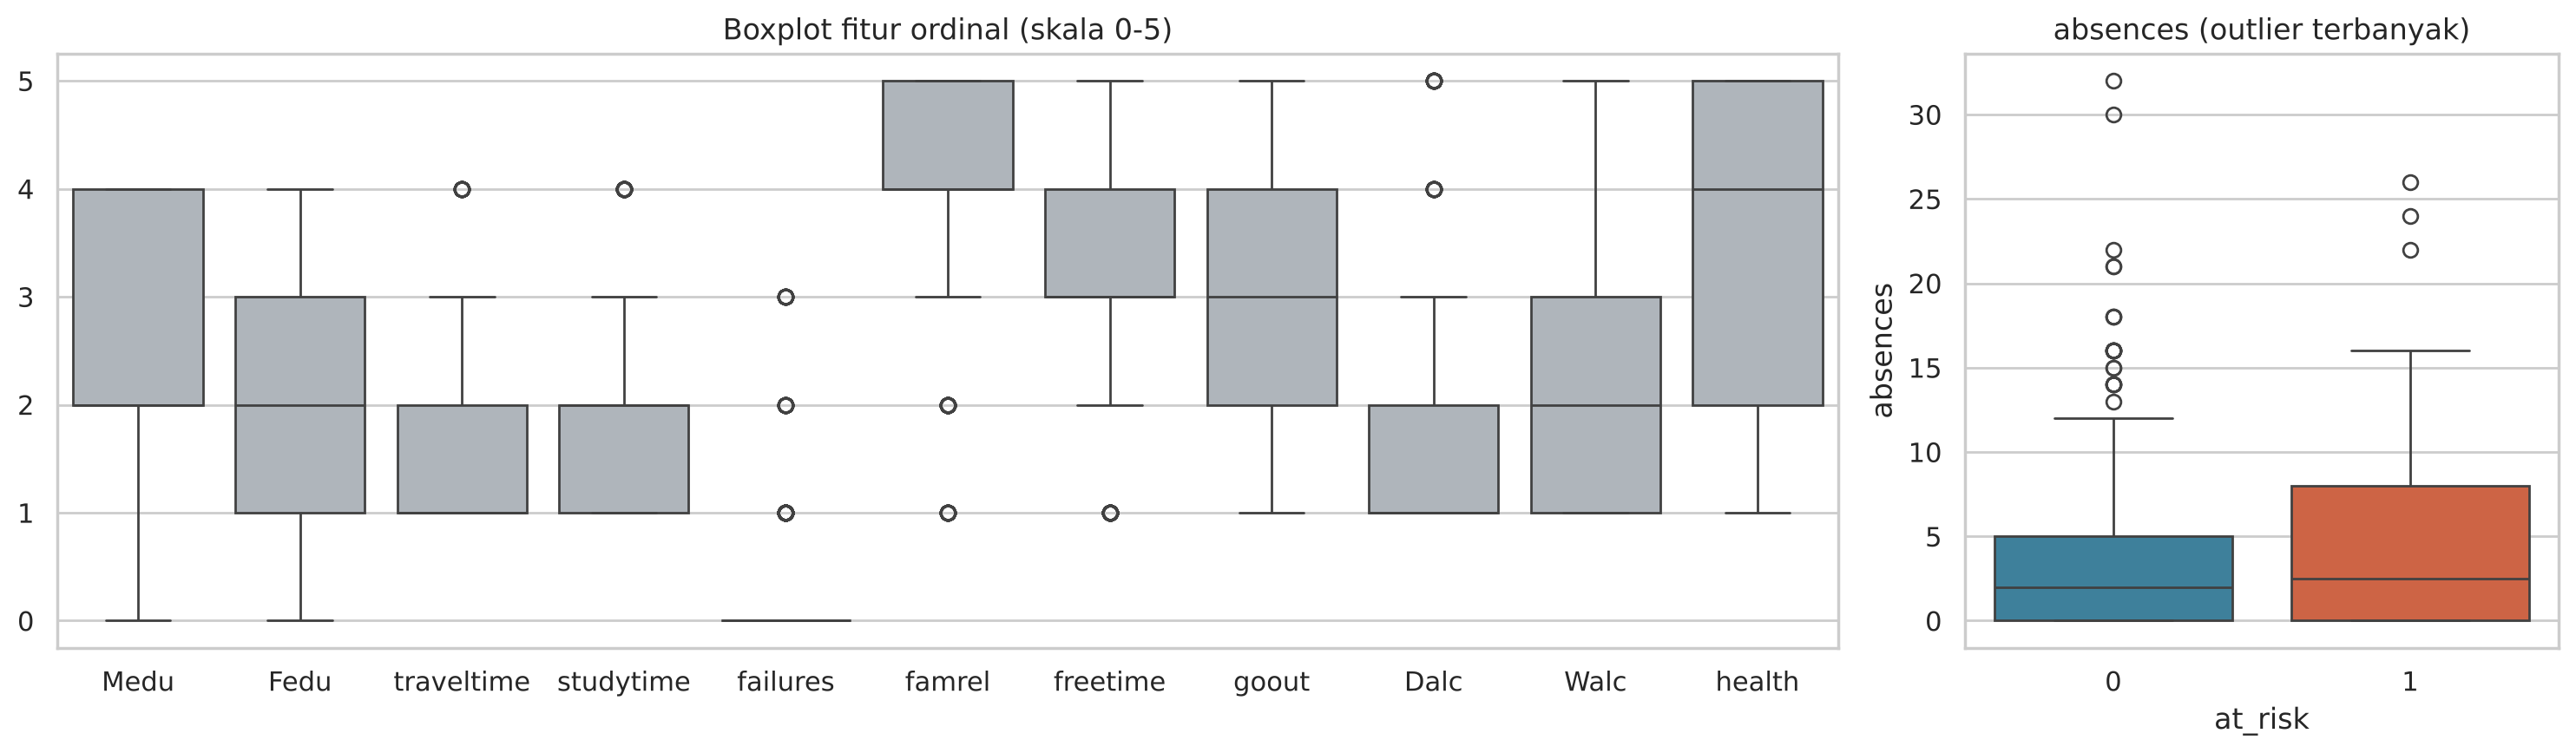

Outlier absences: 21 siswa, rentang 16-32, % berisiko di kelompok outlier = 23.8% (vs 15.4% keseluruhan)
Keputusan: outlier DIPERTAHANKAN (nilai valid & informatif), efeknya diredam StandardScaler + BatchNorm.


In [18]:
out_rows = []
for c in NUMERIC_COLS:
    q1, q3 = df[c].quantile([.25, .75]); iqr = q3 - q1; lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n = int(((df[c] < lo) | (df[c] > hi)).sum())
    out_rows.append({"kolom": c, "Q1": q1, "Q3": q3, "IQR": iqr, "batas_bawah": lo, "batas_atas": hi, "n_outlier": n, "persen": round(n / len(df) * 100, 2)})
out_tbl = pd.DataFrame(out_rows); display(out_tbl)
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw={"width_ratios": [3, 1]})
sns.boxplot(data=df[[c for c in NUMERIC_COLS if c not in ["absences", "age", "G1", "G2"]]], ax=ax[0], color="#ADB5BD")
ax[0].set_title("Boxplot fitur ordinal (skala 0-5)")
sns.boxplot(data=df, x="at_risk", y="absences", hue="at_risk", palette=[C_SAFE, C_RISK], legend=False, ax=ax[1])
ax[1].set_title("absences (outlier terbanyak)")
savefig("14_outlier_boxplot")
abs_out = df[df["absences"] > out_tbl.set_index("kolom").loc["absences", "batas_atas"]]
print(f"Outlier absences: {len(abs_out)} siswa, rentang {abs_out.absences.min()}-{abs_out.absences.max()}, "
      f"% berisiko di kelompok outlier = {abs_out.at_risk.mean()*100:.1f}% (vs {df.at_risk.mean()*100:.1f}% keseluruhan)")
print("Keputusan: outlier DIPERTAHANKAN (nilai valid & informatif), efeknya diredam StandardScaler + BatchNorm.")
PREP["outliers"] = out_tbl.round(3).to_dict("records")
PREP["absences_outlier"] = {"n": int(len(abs_out)), "min": int(abs_out.absences.min()), "max": int(abs_out.absences.max()),
                            "risk_pct": round(float(abs_out.at_risk.mean() * 100), 2), "risk_pct_all": round(float(df.at_risk.mean() * 100), 2)}

### Tahap 3.7 — Pembentukan label & seleksi fitur

In [19]:
print(f"Label: at_risk = 1 jika G3 < {PASS_MARK}")
print(df["at_risk"].value_counts().rename(index=LABELS))
dropped = [c for c in df.columns if c not in FEATURES + ["at_risk"]]
print("Kolom yang TIDAK dipakai sebagai fitur:", dropped, "(G3 = sumber label -> mencegah kebocoran)")
print(f"Jumlah fitur: {len(FEATURES)} = {len(NUMERIC_COLS)} numerik + {len(BINARY_COLS)} biner + {len(NOMINAL_COLS)} nominal")
X = df[FEATURES].copy(); y = df["at_risk"].values
print("X:", X.shape, "| y:", y.shape)
PREP["label"] = {"dropped": dropped, "X_shape": list(X.shape)}

Label: at_risk = 1 jika G3 < 10
at_risk
Tidak Berisiko    549
Berisiko          100
Name: count, dtype: int64
Kolom yang TIDAK dipakai sebagai fitur: ['G3'] (G3 = sumber label -> mencegah kebocoran)
Jumlah fitur: 32 = 15 numerik + 13 biner + 4 nominal
X: (649, 32) | y: (649,)


### Tahap 3.8 — Pembagian data stratified (train/validation/test = 60/20/20)

In [20]:
X_tmp, X_test, y_tmp, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(X_tmp, y_tmp, test_size=0.25, stratify=y_tmp, random_state=SEED)
split_df = pd.DataFrame({
    "n": [len(y_train), len(y_val), len(y_test)],
    "berisiko": [int(y_train.sum()), int(y_val.sum()), int(y_test.sum())],
}, index=["train", "val", "test"])
split_df["persen_data"] = (split_df["n"] / len(y) * 100).round(1)
split_df["persen_berisiko"] = (split_df["berisiko"] / split_df["n"] * 100).round(2)
print(split_df)
assert not set(X_train.index) & set(X_val.index) and not set(X_train.index) & set(X_test.index) and not set(X_val.index) & set(X_test.index)
print("Cek leakage: tidak ada indeks yang tumpang tindih antar split. G3 tidak dipakai sebagai fitur:", "G3" not in FEATURES)

         n  berisiko  persen_data  persen_berisiko
train  389        60         59.9            15.42
val    130        20         20.0            15.38
test   130        20         20.0            15.38
Cek leakage: tidak ada indeks yang tumpang tindih antar split. G3 tidak dipakai sebagai fitur: True


### Tahap 3.9 — Encoding fitur kategorikal (fit pada training)

In [21]:
enc_bin = OneHotEncoder(drop="if_binary", handle_unknown="ignore", sparse_output=False).fit(X_train[BINARY_COLS])
enc_nom = OneHotEncoder(handle_unknown="ignore", sparse_output=False).fit(X_train[NOMINAL_COLS])
bin_map = pd.DataFrame([{"kolom": c, "kategori": list(cats), "dibuang (referensi)": cats[int(d)] if d is not None else "-",
                         "kolom_hasil": [n for n in enc_bin.get_feature_names_out() if n.startswith(c + "_")][0]}
                        for c, cats, d in zip(BINARY_COLS, enc_bin.categories_, enc_bin.drop_idx_ if enc_bin.drop_idx_ is not None else [None] * len(BINARY_COLS))])
nom_map = pd.DataFrame([{"kolom": c, "n_kategori": len(cats), "kolom_hasil": ", ".join(n for n in enc_nom.get_feature_names_out() if n.startswith(c + "_"))}
                        for c, cats in zip(NOMINAL_COLS, enc_nom.categories_)])
display(bin_map); display(nom_map)
print(f"Biner: {len(BINARY_COLS)} kolom -> {len(enc_bin.get_feature_names_out())} kolom 0/1 | "
      f"Nominal: {len(NOMINAL_COLS)} kolom -> {len(enc_nom.get_feature_names_out())} kolom one-hot")
PREP["encoding"] = {"binary_in": len(BINARY_COLS), "binary_out": int(len(enc_bin.get_feature_names_out())),
                    "nominal_in": len(NOMINAL_COLS), "nominal_out": int(len(enc_nom.get_feature_names_out())),
                    "binary_map": bin_map.astype(str).to_dict("records"), "nominal_map": nom_map.astype(str).to_dict("records")}

,kolom,kategori,dibuang (referensi),kolom_hasil
0,school,"[GP, MS]",GP,school_MS
1,sex,"[F, M]",F,sex_M
2,address,"[R, U]",R,address_U
3,famsize,"[GT3, LE3]",GT3,famsize_LE3
4,Pstatus,"[A, T]",A,Pstatus_T
5,schoolsup,"[no, yes]",no,schoolsup_yes
6,famsup,"[no, yes]",no,famsup_yes
7,paid,"[no, yes]",no,paid_yes
8,activities,"[no, yes]",no,activities_yes
9,nursery,"[no, yes]",no,nursery_yes


,kolom,n_kategori,kolom_hasil
0,Mjob,5,"Mjob_at_home, Mjob_health, Mjob_other, Mjob_se..."
1,Fjob,5,"Fjob_at_home, Fjob_health, Fjob_other, Fjob_se..."
2,reason,4,"reason_course, reason_home, reason_other, reas..."
3,guardian,3,"guardian_father, guardian_mother, guardian_other"


Biner: 13 kolom -> 13 kolom 0/1 | Nominal: 4 kolom -> 17 kolom one-hot


### Tahap 3.10 — Standardisasi fitur numerik (z-score, fit pada training)

,mean_train_asli,std_train_asli,mean_train_scaled,std_train_scaled,mean_test_scaled
age,16.704,1.222,-0.0,1.0,0.129
Medu,2.563,1.131,0.0,1.0,-0.117
Fedu,2.332,1.097,-0.0,1.0,-0.085
traveltime,1.584,0.773,-0.0,1.0,-0.068
studytime,1.954,0.819,-0.0,1.0,0.075
failures,0.257,0.662,0.0,1.0,-0.179
famrel,3.907,0.960,0.0,1.0,0.128
freetime,3.165,1.060,0.0,1.0,0.048
goout,3.185,1.152,-0.0,1.0,0.046
Dalc,1.499,0.958,-0.0,1.0,0.050


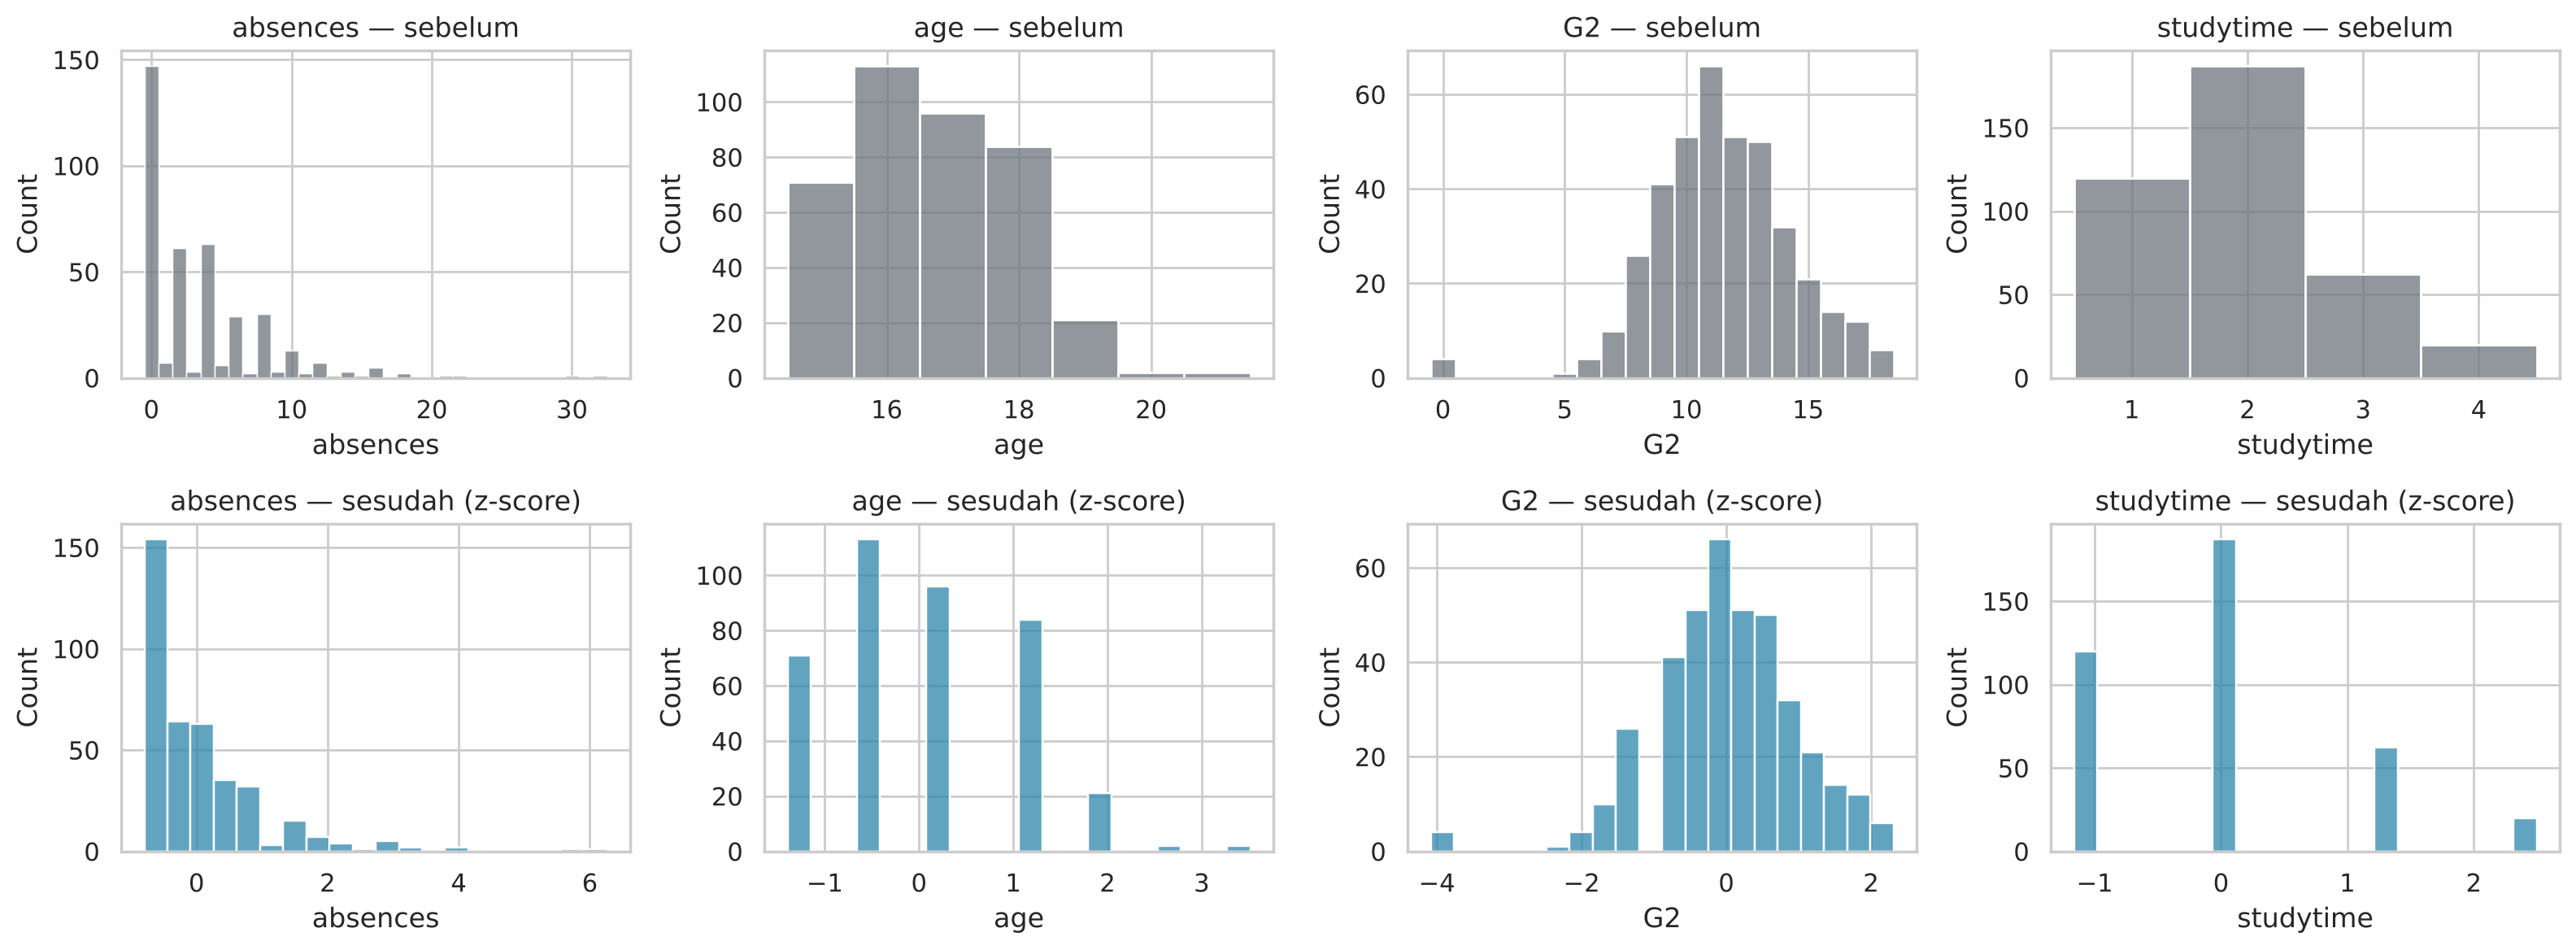

In [22]:
scaler_demo = StandardScaler().fit(X_train[NUMERIC_COLS])
Ztr = pd.DataFrame(scaler_demo.transform(X_train[NUMERIC_COLS]), columns=NUMERIC_COLS)
Zte = pd.DataFrame(scaler_demo.transform(X_test[NUMERIC_COLS]), columns=NUMERIC_COLS)
scale_tbl = pd.DataFrame({"mean_train_asli": X_train[NUMERIC_COLS].mean(), "std_train_asli": X_train[NUMERIC_COLS].std(ddof=0),
                          "mean_train_scaled": Ztr.mean().values, "std_train_scaled": Ztr.std(ddof=0).values,
                          "mean_test_scaled": Zte.mean().values}).round(3)
display(scale_tbl)
fig, ax = plt.subplots(2, 4, figsize=(16, 6))
for j, c in enumerate(["absences", "age", "G2", "studytime"]):
    sns.histplot(X_train[c], ax=ax[0, j], color="#6C757D", discrete=True); ax[0, j].set_title(f"{c} — sebelum")
    sns.histplot(Ztr[c], ax=ax[1, j], color=C_SAFE, bins=20); ax[1, j].set_title(f"{c} — sesudah (z-score)")
savefig("15_standardisasi_sebelum_sesudah")
PREP["scaling"] = scale_tbl.reset_index().rename(columns={"index": "kolom"}).to_dict("records")

### Tahap 3.11 — Pipeline preprocessing gabungan (ColumnTransformer)

In [23]:
preprocessor = ColumnTransformer([
    ("num", StandardScaler(), NUMERIC_COLS),
    ("bin", OneHotEncoder(drop="if_binary", handle_unknown="ignore"), BINARY_COLS),
    ("nom", OneHotEncoder(handle_unknown="ignore"), NOMINAL_COLS),
], sparse_threshold=0)
Xtr = preprocessor.fit_transform(X_train).astype("float32")
Xva = preprocessor.transform(X_val).astype("float32")
Xte = preprocessor.transform(X_test).astype("float32")
FEAT_OUT = list(preprocessor.get_feature_names_out())
N_INPUT = Xtr.shape[1]
print("Shape  X_train:", X_train.shape, "->", Xtr.shape, "| X_val:", X_val.shape, "->", Xva.shape, "| X_test:", X_test.shape, "->", Xte.shape)
print("dtype:", Xtr.dtype, "| NaN:", int(np.isnan(Xtr).sum() + np.isnan(Xva).sum() + np.isnan(Xte).sum()),
      "| Inf:", int(np.isinf(Xtr).sum()))
assert np.allclose(Xtr[:, :len(NUMERIC_COLS)], Ztr.values, atol=1e-5)   # sama dengan tahap 3.10

# contoh satu siswa: sebelum vs sesudah preprocessing
ex_before = X_train.iloc[0]
ex_after = pd.Series(Xtr[0], index=FEAT_OUT)
display(ex_before.to_frame("sebelum").T)
display(ex_after.round(3).to_frame("sesudah").T)

# pemetaan kolom hasil encoding -> fitur asli (dipakai untuk Integrated Gradients)
def orig_feature(name):
    core = name.split("__", 1)[1]
    return max([c for c in FEATURES if core == c or core.startswith(c + "_")], key=len)
GROUPS = [orig_feature(n) for n in FEAT_OUT]
PREP["final"] = {"n_input": N_INPUT, "train": list(Xtr.shape), "val": list(Xva.shape), "test": list(Xte.shape), "dtype": str(Xtr.dtype),
                 "nan": int(np.isnan(Xtr).sum() + np.isnan(Xva).sum() + np.isnan(Xte).sum()),
                 "n_num": len(NUMERIC_COLS), "n_bin_out": PREP["encoding"]["binary_out"], "n_nom_out": PREP["encoding"]["nominal_out"],
                 "example_before": ex_before.astype(str).to_dict(), "example_after": {k: round(float(v), 3) for k, v in ex_after.items()},
                 "feature_out": FEAT_OUT}

Shape  X_train: (389, 32) -> (389, 45) | X_val: (130, 32) -> (130, 45) | X_test: (130, 32) -> (130, 45)
dtype: float32 | NaN: 0 | Inf: 0


,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,...,paid,activities,nursery,higher,internet,romantic,Mjob,Fjob,reason,guardian
sebelum,16,3,2,1,2,0,1,2,2,1,...,no,no,yes,yes,yes,no,other,other,reputation,mother


,num__age,num__Medu,num__Fedu,num__traveltime,num__studytime,num__failures,num__famrel,num__freetime,num__goout,num__Dalc,...,nom__Fjob_other,nom__Fjob_services,nom__Fjob_teacher,nom__reason_course,nom__reason_home,nom__reason_other,nom__reason_reputation,nom__guardian_father,nom__guardian_mother,nom__guardian_other
sesudah,-0.576,0.386,-0.302,-0.755,0.056,-0.389,-3.028,-1.098,-1.028,-0.52,...,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0


### Tahap 3.12 — Penanganan ketidakseimbangan kelas (level fungsi loss)

In [24]:
POS_RATE = float(y_train.mean())
FOCAL_ALPHA = round(1 - POS_RATE, 4)
CLASS_WEIGHT = {0: 1 / (2 * (1 - POS_RATE)), 1: 1 / (2 * POS_RATE)}
imb_tbl = pd.DataFrame({"jumlah_train": [int((y_train == 0).sum()), int((y_train == 1).sum())],
                        "proporsi": [round(1 - POS_RATE, 4), round(POS_RATE, 4)],
                        "class_weight": [round(CLASS_WEIGHT[0], 4), round(CLASS_WEIGHT[1], 4)],
                        "alpha_focal": [round(1 - FOCAL_ALPHA, 4), FOCAL_ALPHA]}, index=[LABELS[0], LABELS[1]])
display(imb_tbl)
print("Augmentasi/oversampling: TIDAK dilakukan (data tabular kecil); imbalance ditangani oleh Focal Loss (fitur unik #1).")
PREP["imbalance"] = imb_tbl.reset_index().rename(columns={"index": "kelas"}).to_dict("records")
json.dump(PREP, open("results/preprocessing.json", "w"), indent=2, default=str)

,jumlah_train,proporsi,class_weight,alpha_focal
Tidak Berisiko,329,0.8458,0.5912,0.1542
Berisiko,60,0.1542,3.2417,0.8458


Augmentasi/oversampling: TIDAK dilakukan (data tabular kecil); imbalance ditangani oleh Focal Loss (fitur unik #1).


## 4. Model: Multilayer Perceptron (Deep Neural Network)

In [25]:
# Konfigurasi utama dipilih dari skenario 7b berdasarkan rata-rata F1 pada data VALIDATION (bukan test)
BASE_CFG = dict(units=(64, 32), dropout=0.3, l2=1e-3, lr=1e-2, batch_size=32, epochs=200,
                loss="focal", gamma=2.0, patience=25)

def build_mlp(n_input, units=(64, 32), dropout=0.3, l2=1e-3, name="student_risk_mlp"):
    inp = keras.Input(shape=(n_input,), name="fitur_siswa")
    x = inp
    for i, u in enumerate(units, 1):
        x = keras.layers.Dense(u, kernel_regularizer=keras.regularizers.l2(l2), name=f"dense_{i}")(x)
        x = keras.layers.BatchNormalization(name=f"batchnorm_{i}")(x)
        x = keras.layers.Activation("relu", name=f"relu_{i}")(x)
        x = keras.layers.Dropout(dropout, name=f"dropout_{i}")(x)
    out = keras.layers.Dense(1, activation="sigmoid", name="prob_berisiko")(x)
    return keras.Model(inp, out, name=name)

def get_loss(kind, gamma=2.0):
    if kind == "focal":
        return keras.losses.BinaryFocalCrossentropy(apply_class_balancing=True, alpha=FOCAL_ALPHA, gamma=gamma), None
    if kind == "wbce":
        return keras.losses.BinaryCrossentropy(), CLASS_WEIGHT
    return keras.losses.BinaryCrossentropy(), None

set_seed()
_m = build_mlp(N_INPUT, BASE_CFG["units"], BASE_CFG["dropout"], BASE_CFG["l2"])
_m.summary()
ARCH_TABLE = [{"layer": l.name, "type": l.__class__.__name__, "output": str(tuple(l.output.shape)), "params": int(l.count_params())} for l in _m.layers]
N_PARAMS = {"total": int(_m.count_params()),
            "trainable": int(sum(np.prod(w.shape) for w in _m.trainable_weights)),
            "non_trainable": int(sum(np.prod(w.shape) for w in _m.non_trainable_weights))}
print(N_PARAMS)

Model: "student_risk_mlp"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ fitur_siswa (InputLayer)        │ (None, 45)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         2,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batchnorm_1                     │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu_1 (Activation)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batchnorm_2                     │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu_2 (Activation)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ prob_berisiko (Dense)           │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,441 (21.25 KB)

 Trainable params: 5,249 (20.50 KB)

 Non-trainable params: 192 (768.00 B)

{'total': 5441, 'trainable': 5249, 'non_trainable': 192}


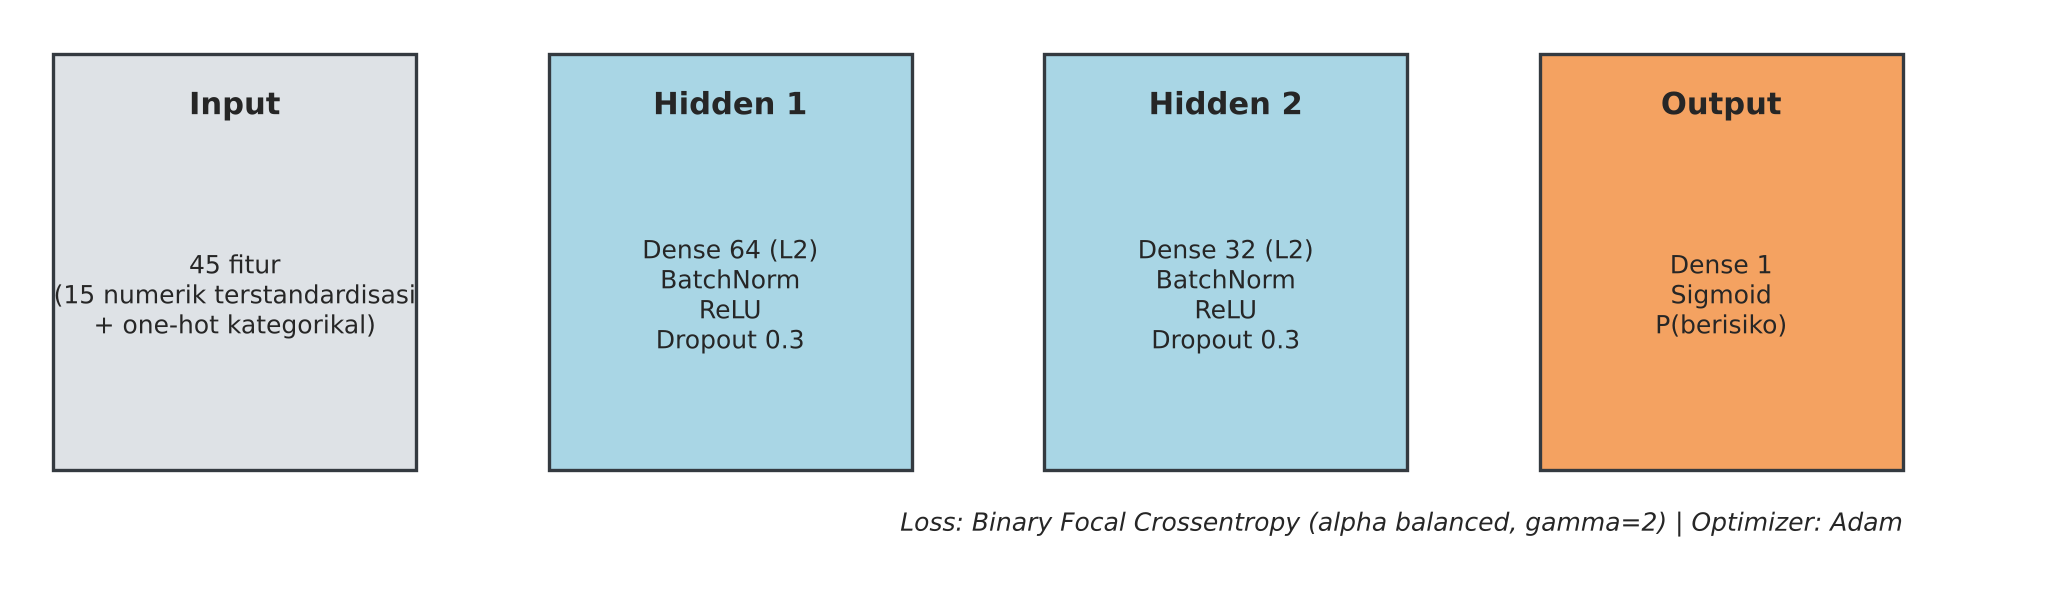

In [26]:
# Diagram arsitektur
def draw_architecture(n_input, units, dropout, path):
    blocks = [("Input", f"{n_input} fitur\n(15 numerik terstandardisasi\n+ one-hot kategorikal)", "#DEE2E6")]
    for i, u in enumerate(units, 1):
        blocks.append((f"Hidden {i}", f"Dense {u} (L2)\nBatchNorm\nReLU\nDropout {dropout}", "#A9D6E5"))
    blocks.append(("Output", "Dense 1\nSigmoid\nP(berisiko)", "#F4A261"))
    fig, ax = plt.subplots(figsize=(13, 3.6)); ax.axis("off")
    w, gap = 2.2, 0.8
    for i, (t, s, c) in enumerate(blocks):
        x0 = i * (w + gap)
        ax.add_patch(plt.Rectangle((x0, 0), w, 2.4, color=c, ec="#343A40", lw=1.2))
        ax.text(x0 + w / 2, 2.1, t, ha="center", va="center", fontweight="bold", fontsize=11)
        ax.text(x0 + w / 2, 1.0, s, ha="center", va="center", fontsize=9)
        if i < len(blocks) - 1:
            ax.annotate("", xy=(x0 + w + gap, 1.2), xytext=(x0 + w, 1.2), arrowprops=dict(arrowstyle="->", lw=1.5))
    ax.text(len(blocks) * (w + gap) - gap, -0.35, "Loss: Binary Focal Crossentropy (alpha balanced, gamma=2) | Optimizer: Adam", ha="right", fontsize=9, style="italic")
    ax.set_xlim(-0.2, len(blocks) * (w + gap)); ax.set_ylim(-0.6, 2.6)
    plt.savefig(path, dpi=150, bbox_inches="tight"); plt.show()
draw_architecture(N_INPUT, BASE_CFG["units"], BASE_CFG["dropout"], "figures/06_arsitektur_mlp.png")

## 5. Training

In [27]:
def evaluate_probs(y_true, prob, threshold=0.5):
    yp = (prob >= threshold).astype(int)
    return {"accuracy": accuracy_score(y_true, yp),
            "precision": precision_score(y_true, yp, zero_division=0),
            "recall": recall_score(y_true, yp, zero_division=0),
            "f1": f1_score(y_true, yp, zero_division=0),
            "f1_macro": f1_score(y_true, yp, average="macro", zero_division=0),
            "roc_auc": roc_auc_score(y_true, prob),
            "pr_auc": average_precision_score(y_true, prob)}

def train_mlp(Xtr, ytr, Xva, yva, seed=SEED, verbose=0, **kw):
    cfg = {**BASE_CFG, **kw}
    set_seed(seed)
    model = build_mlp(Xtr.shape[1], cfg["units"], cfg["dropout"], cfg["l2"])
    loss, cw = get_loss(cfg["loss"], cfg["gamma"])
    model.compile(optimizer=keras.optimizers.Adam(cfg["lr"]), loss=loss,
                  metrics=[keras.metrics.AUC(name="auc"), keras.metrics.BinaryAccuracy(name="accuracy"),
                           keras.metrics.Recall(name="recall"), keras.metrics.Precision(name="precision")])
    cbs = [keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=cfg["patience"], restore_best_weights=True),
           keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=10, min_lr=1e-5)]
    hist = model.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=cfg["epochs"], batch_size=cfg["batch_size"],
                     class_weight=cw, callbacks=cbs, verbose=verbose, shuffle=True)
    return model, hist.history

model, history = train_mlp(Xtr, y_train, Xva, y_val, seed=SEED, verbose=0)
EPOCHS_RUN = len(history["loss"]); BEST_EPOCH = int(np.argmax(history["val_auc"]) + 1)
print(f"Epoch dijalankan: {EPOCHS_RUN} | epoch terbaik (val_auc maks, bobot dipulihkan): {BEST_EPOCH}")
pd.DataFrame(history).to_csv("results/history_main.csv", index_label="epoch")

E0000 00:00:1793991745.684413     265 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


Epoch dijalankan: 36 | epoch terbaik (val_auc maks, bobot dipulihkan): 11


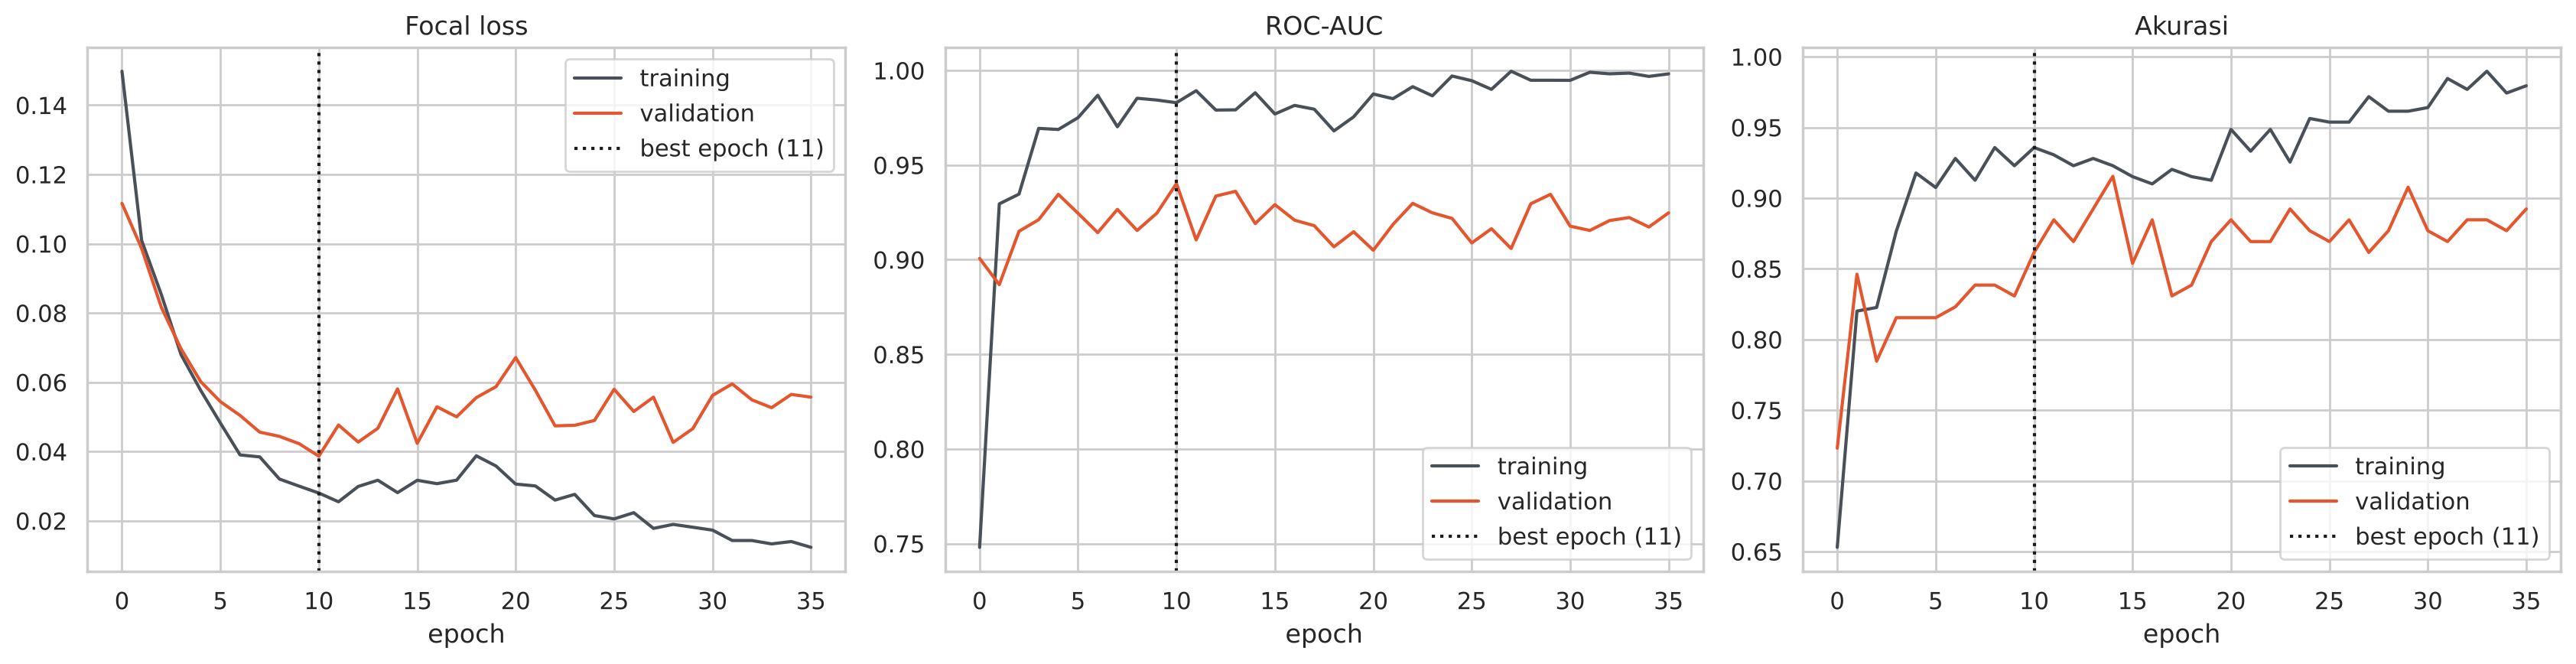

In [28]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
for a, (m, t) in zip(ax, [("loss", "Focal loss"), ("auc", "ROC-AUC"), ("accuracy", "Akurasi")]):
    a.plot(history[m], label="training", color="#495057")
    a.plot(history["val_" + m], label="validation", color=C_RISK)
    a.axvline(BEST_EPOCH - 1, ls=":", color="k", label=f"best epoch ({BEST_EPOCH})")
    a.set_title(t); a.set_xlabel("epoch"); a.legend()
savefig("07_kurva_training")

## 6. Evaluasi pada Data Testing

In [29]:
THRESHOLD = 0.5
p_train = model.predict(Xtr, verbose=0).ravel()
p_val = model.predict(Xva, verbose=0).ravel()
p_test = model.predict(Xte, verbose=0).ravel()
MAIN = {s: evaluate_probs(yy, pp, THRESHOLD) for s, yy, pp in [("train", y_train, p_train), ("val", y_val, p_val), ("test", y_test, p_test)]}
main_df = pd.DataFrame(MAIN).T.round(4); print(main_df)

y_pred = (p_test >= THRESHOLD).astype(int)
print(classification_report(y_test, y_pred, target_names=[LABELS[0], LABELS[1]], digits=4))
CM = confusion_matrix(y_test, y_pred); tn, fp, fn, tp = CM.ravel()
print(f"TN={tn} FP={fp} FN={fn} TP={tp}")

E0000 00:00:1793991751.376638     265 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


       accuracy  precision  recall      f1  f1_macro  roc_auc  pr_auc
train    0.9486     0.7632  0.9667  0.8529    0.9109   0.9914  0.9647
val      0.8615     0.5333  0.8000  0.6400    0.7771   0.9409  0.8014
test     0.8615     0.5357  0.7500  0.6250    0.7700   0.9182  0.7026
                precision    recall  f1-score   support

Tidak Berisiko     0.9510    0.8818    0.9151       110
      Berisiko     0.5357    0.7500    0.6250        20

      accuracy                         0.8615       130
     macro avg     0.7433    0.8159    0.7700       130
  weighted avg     0.8871    0.8615    0.8705       130

TN=97 FP=13 FN=5 TP=15


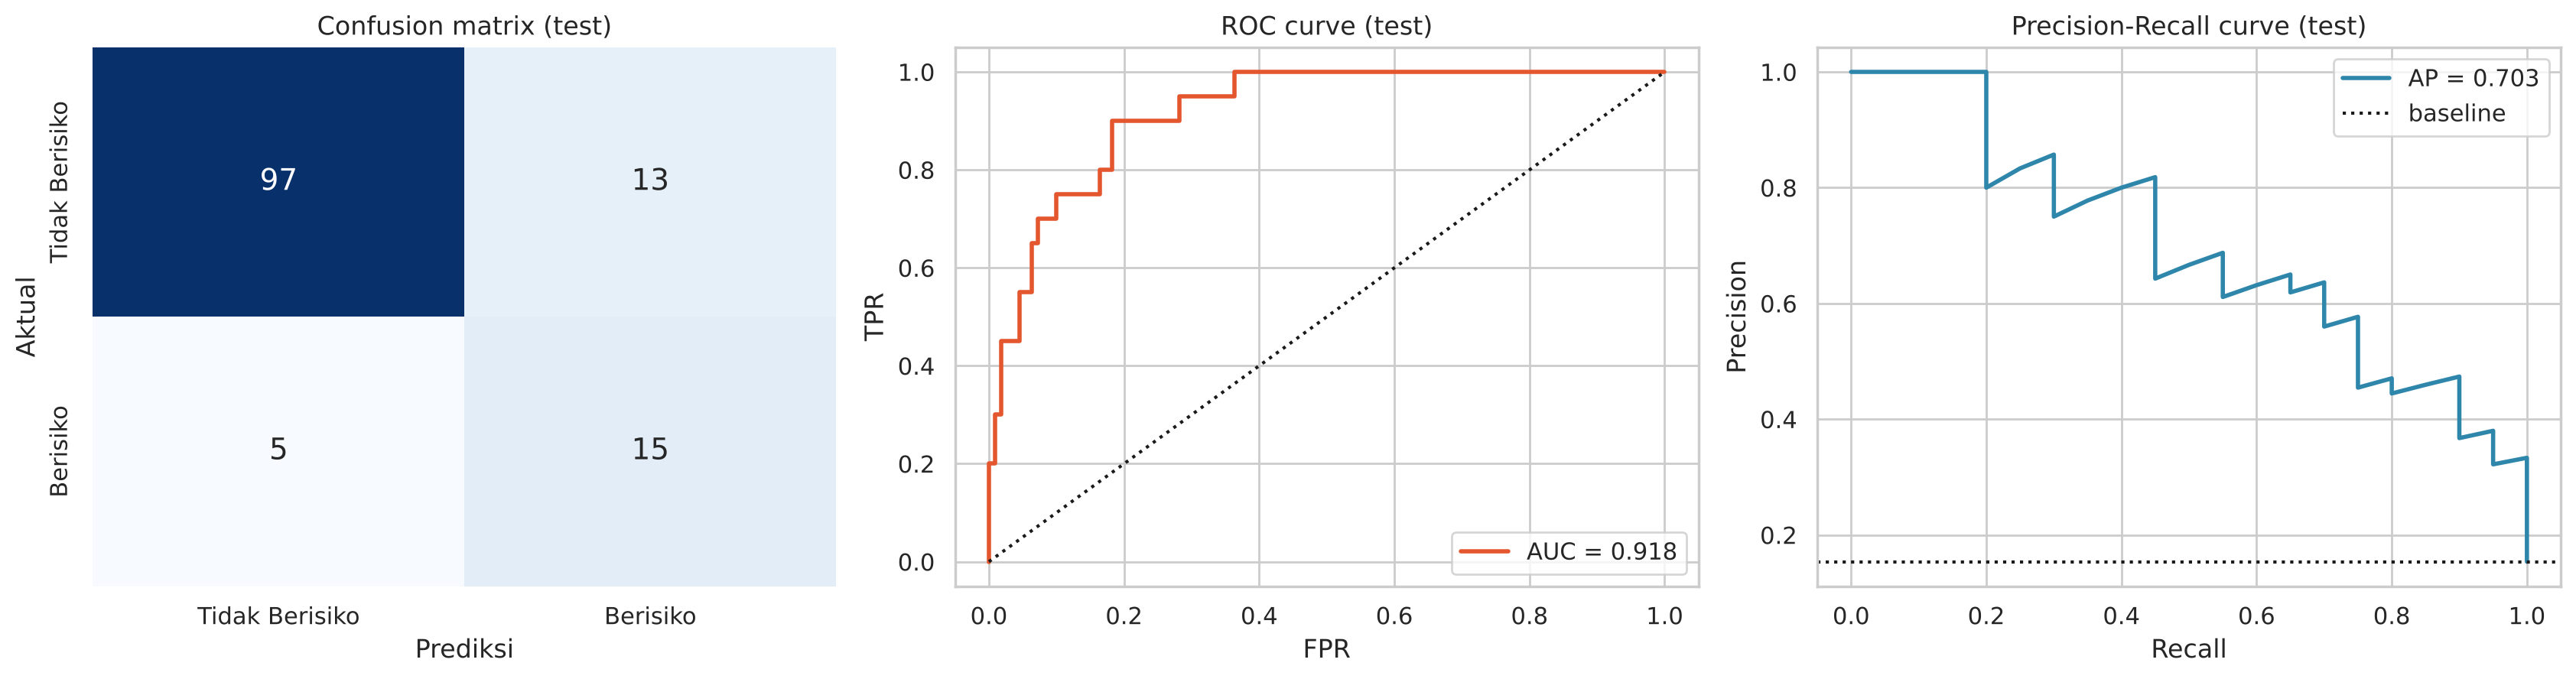

In [30]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
sns.heatmap(CM, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax[0],
            xticklabels=[LABELS[0], LABELS[1]], yticklabels=[LABELS[0], LABELS[1]], annot_kws={"size": 14})
ax[0].set_xlabel("Prediksi"); ax[0].set_ylabel("Aktual"); ax[0].set_title("Confusion matrix (test)")
fpr, tpr, _ = roc_curve(y_test, p_test)
ax[1].plot(fpr, tpr, color=C_RISK, lw=2, label=f"AUC = {MAIN['test']['roc_auc']:.3f}"); ax[1].plot([0, 1], [0, 1], "k:")
ax[1].set_title("ROC curve (test)"); ax[1].set_xlabel("FPR"); ax[1].set_ylabel("TPR"); ax[1].legend()
pr, rc, _ = precision_recall_curve(y_test, p_test)
ax[2].plot(rc, pr, color=C_SAFE, lw=2, label=f"AP = {MAIN['test']['pr_auc']:.3f}")
ax[2].axhline(y_test.mean(), ls=":", color="k", label="baseline")
ax[2].set_title("Precision-Recall curve (test)"); ax[2].set_xlabel("Recall"); ax[2].set_ylabel("Precision"); ax[2].legend()
savefig("08_confusion_roc_pr")

## 7. Perbandingan Antarskenario (5 seed per skenario, split data tetap)

In [31]:
SEEDS = [42, 7, 21, 77, 123]

def run_scenario(name, Xtr_, Xva_, Xte_, **kw):
    rows = []
    for s in SEEDS:
        m, h = train_mlp(Xtr_, y_train, Xva_, y_val, seed=s, **kw)
        r = evaluate_probs(y_test, m.predict(Xte_, verbose=0).ravel())
        rv = evaluate_probs(y_val, m.predict(Xva_, verbose=0).ravel())
        r.update(val_f1=rv["f1"], val_roc_auc=rv["roc_auc"], val_pr_auc=rv["pr_auc"])
        r.update(seed=s, epochs=len(h["loss"]), scenario=name); rows.append(r)
        keras.backend.clear_session()
    return rows

def summarize(rows):
    d = pd.DataFrame(rows)
    agg = d.groupby("scenario", sort=False)[["val_f1", "val_pr_auc", "accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc", "epochs"]].agg(["mean", "std"])
    return d, agg

# 7a. Fitur unik #1 -> pengaruh fungsi loss untuk data tidak seimbang
loss_rows = []
for nm, lk in [("BCE (tanpa penanganan imbalance)", "bce"), ("Weighted BCE (class weight)", "wbce"), ("Focal Loss (usulan)", "focal")]:
    loss_rows += run_scenario(nm, Xtr, Xva, Xte, loss=lk)
loss_raw, loss_agg = summarize(loss_rows)
loss_agg.round(4)

E0000 00:00:1793991757.507698     265 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


E0000 00:00:1793991764.566992     265 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


E0000 00:00:1793991770.223439     265 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


E0000 00:00:1793991776.029574     265 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


E0000 00:00:1793991783.050058     265 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


E0000 00:00:1793991788.154425     265 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


... (3 outputs left out)

E0000 00:00:1793991813.748183     265 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


E0000 00:00:1793991819.041196     265 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


E0000 00:00:1793991824.964627     265 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


val_f1         val_pr_auc         accuracy  \
                                    mean     std       mean     std     mean   
scenario                                                                       
BCE (tanpa penanganan imbalance)  0.6328  0.0395     0.7411  0.0660   0.8523   
Weighted BCE (class weight)       0.5553  0.0213     0.7515  0.0301   0.7569   
Focal Loss (usulan)               0.6542  0.0397     0.7825  0.0303   0.8508   

                                         precision         recall          \
                                     std      mean     std   mean     std   
scenario                                                                    
BCE (tanpa penanganan imbalance)  0.0252    0.5208  0.0621   0.87  0.0837   
Weighted BCE (class weight)       0.0556    0.3906  0.0649   0.92  0.0671   
Focal Loss (usulan)               0.0347    0.5208  0.0759   0.85  0.0791   

                                      f1         roc_auc          pr_auc  \
                                    mean     std    mean     std    mean   
scenario                                                                   
BCE (tanpa penanganan imbalance)  0.6462  0.0239  0.9252  0.0104  0.7040   
Weighted BCE (class weight)       0.5432  0.0464  0.9274  0.0094  0.7309   
Focal Loss (usulan)               0.6402  0.0445  0.9219  0.0162  0.7170   

                                         epochs           
                                     std   mean      std  
scenario                                                  
BCE (tanpa penanganan imbalance)  0.0346   30.6   6.3875  
Weighted BCE (class weight)       0.0307   29.4   3.7148  
Focal Loss (usulan)               0.0612   41.6  10.2127

In [32]:
# 7b. Variasi arsitektur & hyperparameter (loss focal)
arch_rows = []
for nm, kw in [("MLP 32-16, dropout 0.3, lr 1e-2", dict(units=(32, 16))),
               ("MLP 64-32, dropout 0.3, lr 1e-2 (utama)", dict()),
               ("MLP 128-64-32, dropout 0.3, lr 1e-2", dict(units=(128, 64, 32))),
               ("MLP 64-32, dropout 0.5, lr 1e-2", dict(dropout=0.5)),
               ("MLP 64-32, lr 1e-3", dict(lr=1e-3))]:
    arch_rows += run_scenario(nm, Xtr, Xva, Xte, **kw)
arch_raw, arch_agg = summarize(arch_rows)
print("Konfigurasi dengan F1 validation tertinggi:", arch_agg[("val_f1", "mean")].idxmax())
arch_agg.round(4)

E0000 00:00:1793991831.401644     265 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


E0000 00:00:1793991836.800262     265 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


E0000 00:00:1793991842.379737     265 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


E0000 00:00:1793991848.152128     265 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


E0000 00:00:1793991855.952164     265 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


E0000 00:00:1793991861.023258     265 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


... (16 outputs left out)

E0000 00:00:1793991961.445684     265 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


E0000 00:00:1793991966.748486     265 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


Konfigurasi dengan F1 validation tertinggi: MLP 64-32, dropout 0.3, lr 1e-2 (utama)


val_f1         val_pr_auc          \
                                           mean     std       mean     std   
scenario                                                                     
MLP 32-16, dropout 0.3, lr 1e-2          0.6216  0.0256     0.7751  0.0221   
MLP 64-32, dropout 0.3, lr 1e-2 (utama)  0.6542  0.0397     0.7825  0.0303   
MLP 128-64-32, dropout 0.3, lr 1e-2      0.6491  0.0373     0.8034  0.0362   
MLP 64-32, dropout 0.5, lr 1e-2          0.6527  0.0114     0.7909  0.0315   
MLP 64-32, lr 1e-3                       0.6364  0.0273     0.7071  0.0319   

                                        accuracy         precision          \
                                            mean     std      mean     std   
scenario                                                                     
MLP 32-16, dropout 0.3, lr 1e-2           0.8538  0.0471    0.5593  0.1438   
MLP 64-32, dropout 0.3, lr 1e-2 (utama)   0.8508  0.0347    0.5208  0.0759   
MLP 128-64-32, dropout 0.3, lr 1e-2       0.8385  0.0400    0.4943  0.0746   
MLP 64-32, dropout 0.5, lr 1e-2           0.8677  0.0561    0.5696  0.1194   
MLP 64-32, lr 1e-3                        0.7954  0.0306    0.4263  0.0364   

                                        recall              f1          \
                                          mean     std    mean     std   
scenario                                                                 
MLP 32-16, dropout 0.3, lr 1e-2           0.79  0.1475  0.6299  0.0398   
MLP 64-32, dropout 0.3, lr 1e-2 (utama)   0.85  0.0791  0.6402  0.0445   
MLP 128-64-32, dropout 0.3, lr 1e-2       0.89  0.0224  0.6332  0.0627   
MLP 64-32, dropout 0.5, lr 1e-2           0.88  0.0570  0.6823  0.0789   
MLP 64-32, lr 1e-3                        0.90  0.0500  0.5768  0.0265   

                                        roc_auc          pr_auc          \
                                           mean     std    mean     std   
scenario                                                                  
MLP 32-16, dropout 0.3, lr 1e-2          0.9294  0.0083  0.7418  0.0282   
MLP 64-32, dropout 0.3, lr 1e-2 (utama)  0.9219  0.0162  0.7170  0.0612   
MLP 128-64-32, dropout 0.3, lr 1e-2      0.9413  0.0055  0.7774  0.0164   
MLP 64-32, dropout 0.5, lr 1e-2          0.9330  0.0110  0.7334  0.0335   
MLP 64-32, lr 1e-3                       0.9054  0.0113  0.6834  0.0666   

                                        epochs           
                                          mean      std  
scenario                                                 
MLP 32-16, dropout 0.3, lr 1e-2           37.2   7.8549  
MLP 64-32, dropout 0.3, lr 1e-2 (utama)   41.6  10.2127  
MLP 128-64-32, dropout 0.3, lr 1e-2       42.6  10.6442  
MLP 64-32, dropout 0.5, lr 1e-2           38.8   8.8994  
MLP 64-32, lr 1e-3                        40.4   4.4497

In [33]:
# 7c. Skenario ketersediaan fitur nilai (early warning): tanpa nilai / +G1 / +G1+G2 (utama)
def make_xy(drop_cols):
    num = [c for c in NUMERIC_COLS if c not in drop_cols]
    ct = ColumnTransformer([("num", StandardScaler(), num),
                            ("bin", OneHotEncoder(drop="if_binary", handle_unknown="ignore"), BINARY_COLS),
                            ("nom", OneHotEncoder(handle_unknown="ignore"), NOMINAL_COLS)], sparse_threshold=0)
    cols = num + BINARY_COLS + NOMINAL_COLS
    return (ct.fit_transform(X_train[cols]).astype("float32"), ct.transform(X_val[cols]).astype("float32"),
            ct.transform(X_test[cols]).astype("float32"))
feat_rows = []
for nm, drop in [("Tanpa nilai (awal semester)", ["G1", "G2"]), ("+G1 (setelah periode 1)", ["G2"]), ("+G1+G2 (utama, setelah periode 2)", [])]:
    feat_rows += run_scenario(nm, *make_xy(drop))
feat_raw, feat_agg = summarize(feat_rows)
feat_agg.round(4)

E0000 00:00:1793991974.751399     265 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


E0000 00:00:1793991980.874217     265 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


E0000 00:00:1793991986.119733     265 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


E0000 00:00:1793991991.717888     265 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


E0000 00:00:1793991997.219857     265 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


E0000 00:00:1793992002.484292     265 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


... (6 outputs left out)

E0000 00:00:1793992043.378737     265 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


E0000 00:00:1793992048.718622     265 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


E0000 00:00:1793992054.534283     265 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


val_f1         val_pr_auc         accuracy  \
                                     mean     std       mean     std     mean   
scenario                                                                        
Tanpa nilai (awal semester)        0.3519  0.1108     0.3842  0.0141   0.8015   
+G1 (setelah periode 1)            0.5790  0.0299     0.6563  0.0396   0.7969   
+G1+G2 (utama, setelah periode 2)  0.6542  0.0397     0.7825  0.0303   0.8508   

                                          precision         recall          \
                                      std      mean     std   mean     std   
scenario                                                                     
Tanpa nilai (awal semester)        0.0453    0.3137  0.1843   0.41  0.2608   
+G1 (setelah periode 1)            0.0437    0.4201  0.0591   0.70  0.1658   
+G1+G2 (utama, setelah periode 2)  0.0347    0.5208  0.0759   0.85  0.0791   

                                       f1         roc_auc          pr_auc  \
                                     mean     std    mean     std    mean   
scenario                                                                    
Tanpa nilai (awal semester)        0.3435  0.1926  0.7282  0.0378  0.3203   
+G1 (setelah periode 1)            0.5137  0.0402  0.8819  0.0168  0.5835   
+G1+G2 (utama, setelah periode 2)  0.6402  0.0445  0.9219  0.0162  0.7170   

                                          epochs           
                                      std   mean      std  
scenario                                                   
Tanpa nilai (awal semester)        0.0296   43.6  18.0361  
+G1 (setelah periode 1)            0.0586   46.8  12.1943  
+G1+G2 (utama, setelah periode 2)  0.0612   41.6  10.2127

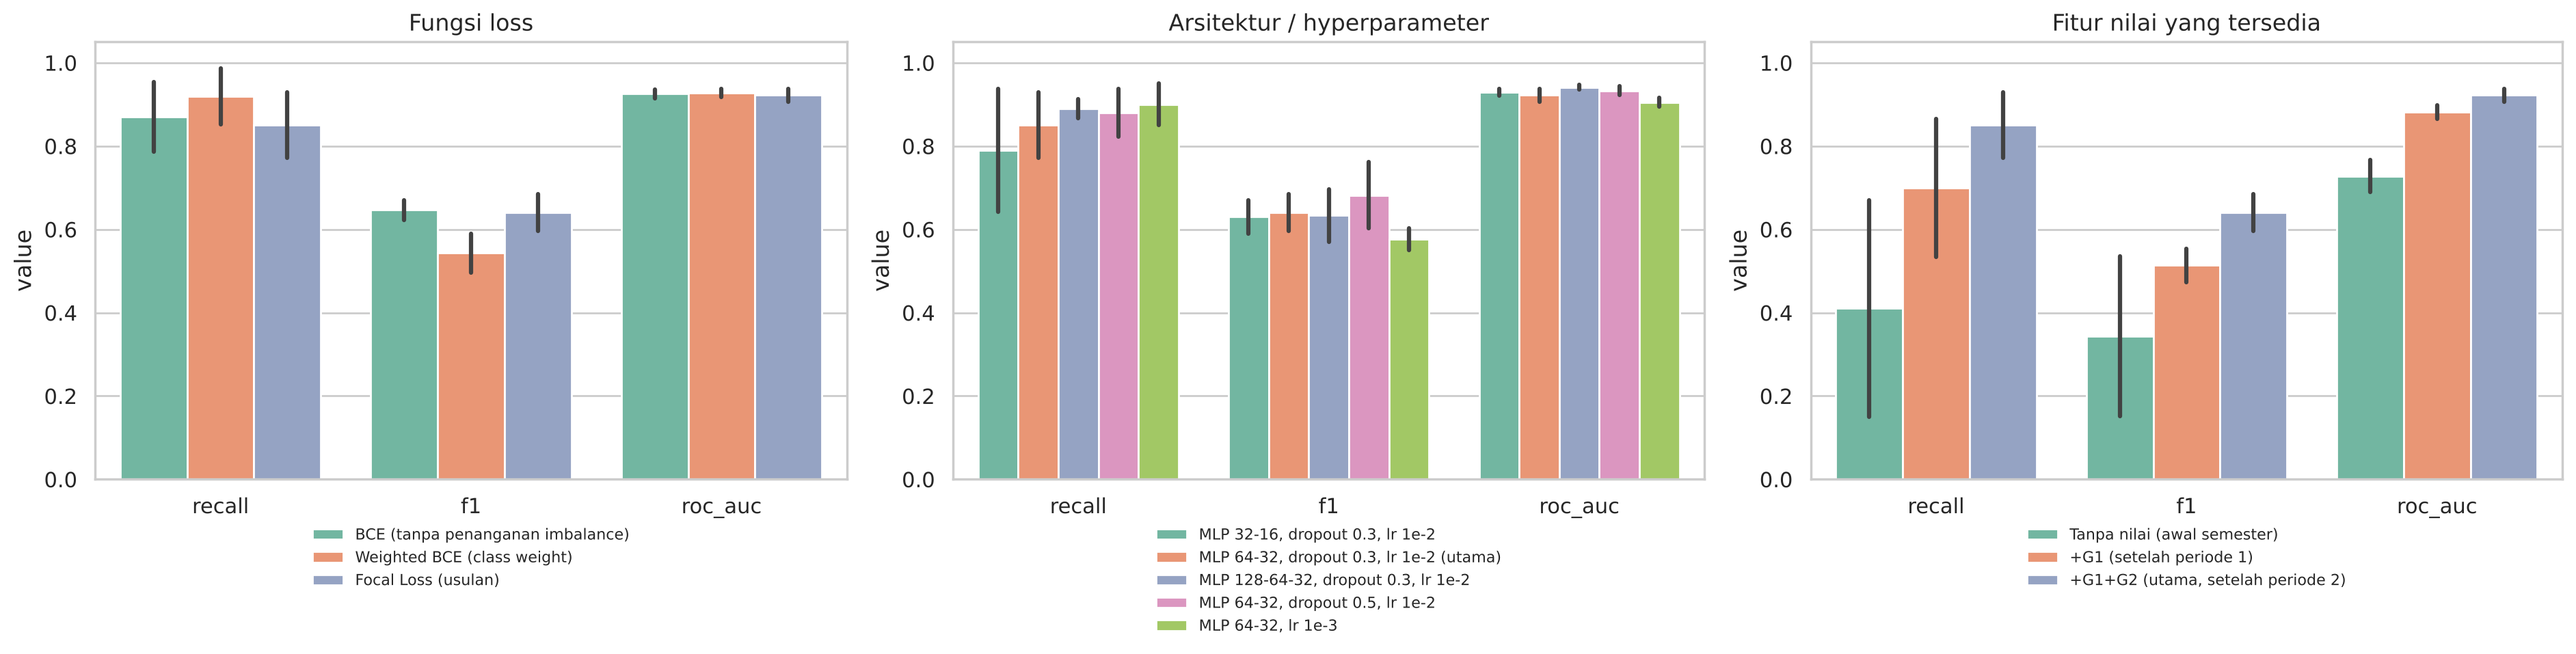

In [34]:
fig, ax = plt.subplots(1, 3, figsize=(19, 5))
for a, (raw, t) in zip(ax, [(loss_raw, "Fungsi loss"), (arch_raw, "Arsitektur / hyperparameter"), (feat_raw, "Fitur nilai yang tersedia")]):
    long = raw.melt(id_vars="scenario", value_vars=["recall", "f1", "roc_auc"], var_name="metrik")
    sns.barplot(data=long, x="metrik", y="value", hue="scenario", errorbar="sd", ax=a, palette="Set2")
    a.set_ylim(0, 1.05); a.set_title(t); a.set_xlabel(""); a.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=1, frameon=False)
savefig("09_perbandingan_skenario")
pd.concat([loss_raw, arch_raw, feat_raw]).to_csv("results/scenario_runs.csv", index=False)

## 8. Analisis Kesalahan & Overfitting

False Negative (siswa berisiko yang terlewat):


,G1,G2,G3,failures,absences,studytime,higher,prob,aktual,prediksi,jenis
256,7,8,8,1,26,1,no,0.477,1,0,FN
646,11,12,9,0,6,2,yes,0.318,1,0,FN
488,7,9,9,1,6,3,no,0.455,1,0,FN
257,10,8,9,0,6,1,yes,0.371,1,0,FN
172,10,10,1,1,0,2,yes,0.473,1,0,FN


False Positive (dikira berisiko):


,G1,G2,G3,failures,absences,studytime,higher,prob,aktual,prediksi,jenis
642,6,9,11,0,0,2,yes,0.711,0,1,FP
578,8,9,10,1,4,2,yes,0.679,0,1,FP
173,9,8,10,2,0,1,yes,0.621,0,1,FP
521,8,10,10,0,0,2,yes,0.614,0,1,FP
552,9,9,10,2,2,2,no,0.603,0,1,FP
184,9,9,10,1,4,1,yes,0.576,0,1,FP
589,7,10,10,0,0,1,yes,0.563,0,1,FP
176,8,9,10,0,2,1,yes,0.555,0,1,FP
531,10,10,10,0,0,2,yes,0.531,0,1,FP
542,10,11,12,0,1,3,yes,0.524,0,1,FP


           n  salah  error_rate_%
band_G3                          
G3=0       4      0           0.0
G3 1-9    16      5          31.2
G3 10-11  39     12          30.8
G3 12-20  71      1           1.4


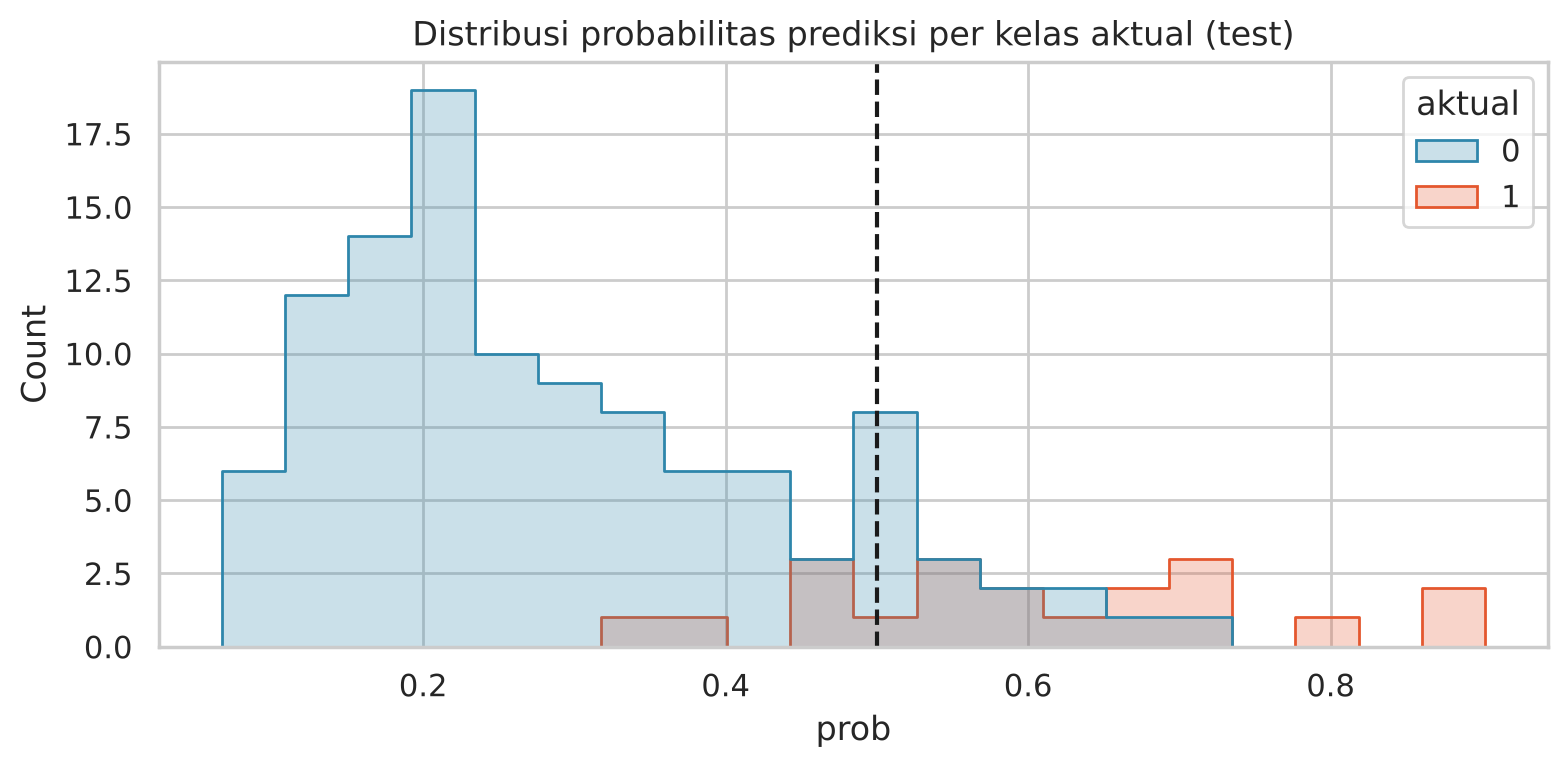

{'auc_train': 0.9914, 'auc_val': 0.9409, 'auc_test': 0.9182, 'loss_train_best': 0.028, 'loss_val_best': 0.0387}


In [35]:
err = X_test.copy()
err["G3"] = df.loc[X_test.index, "G3"].values
err["aktual"] = y_test; err["prob"] = p_test.round(3); err["prediksi"] = y_pred
err["jenis"] = np.select([(err.aktual == 1) & (err.prediksi == 0), (err.aktual == 0) & (err.prediksi == 1)], ["FN", "FP"], "benar")
cols_show = ["G1", "G2", "G3", "failures", "absences", "studytime", "higher", "prob", "aktual", "prediksi", "jenis"]
print("False Negative (siswa berisiko yang terlewat):"); display(err[err.jenis == "FN"][cols_show])
print("False Positive (dikira berisiko):"); display(err[err.jenis == "FP"][cols_show].sort_values("prob", ascending=False))

err["band_G3"] = pd.cut(err["G3"], [-1, 0, 9, 11, 20], labels=["G3=0", "G3 1-9", "G3 10-11", "G3 12-20"])
band = err.groupby("band_G3", observed=False).agg(n=("jenis", "size"), salah=("jenis", lambda s: int((s != "benar").sum())))
band["error_rate_%"] = (band["salah"] / band["n"] * 100).round(1); print(band)

fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(data=err, x="prob", hue="aktual", palette=PALETTE, bins=20, ax=ax, element="step")
ax.axvline(THRESHOLD, color="k", ls="--"); ax.set_title("Distribusi probabilitas prediksi per kelas aktual (test)")
savefig("10_distribusi_probabilitas")

GAP = {"auc_train": MAIN["train"]["roc_auc"], "auc_val": MAIN["val"]["roc_auc"], "auc_test": MAIN["test"]["roc_auc"],
       "loss_train_best": history["loss"][BEST_EPOCH - 1], "loss_val_best": history["val_loss"][BEST_EPOCH - 1]}
print({k: round(v, 4) for k, v in GAP.items()})

## 9. Fitur Unik #2 — Explainable AI dengan Integrated Gradients

In [36]:
BASELINE = Xtr.mean(axis=0).astype("float32")   # baseline = profil "siswa rata-rata" di data training
GROUP_NAMES = list(dict.fromkeys(GROUPS)); GROUP_IDX = {g: [i for i, x in enumerate(GROUPS) if x == g] for g in GROUP_NAMES}

def integrated_gradients(model, X, baseline=BASELINE, steps=64):
    X = np.atleast_2d(X).astype("float32"); out = []
    alphas = tf.reshape(tf.linspace(0.0, 1.0, steps + 1), (-1, 1))
    b = tf.constant(baseline[None, :])
    for x in X:
        x = tf.constant(x[None, :]); path = b + alphas * (x - b)
        with tf.GradientTape() as tape:
            tape.watch(path); pr = model(path, training=False)[:, 0]
        g = tape.gradient(pr, path)
        avg = tf.reduce_mean((g[:-1] + g[1:]) / 2.0, axis=0)
        out.append(((x - b)[0] * avg).numpy())
    return np.array(out)

def group_attr(attr):
    attr = np.atleast_2d(attr)
    return pd.DataFrame({g: attr[:, idx].sum(1) for g, idx in GROUP_IDX.items()})

IG_test = integrated_gradients(model, Xte)
IG_grp = group_attr(IG_test)
p_base = float(model(BASELINE[None], training=False).numpy()[0, 0])
completeness = np.abs(IG_test.sum(1) - (p_test - p_base))
print(f"P(baseline) = {p_base:.4f} | error completeness rata-rata |sum(IG) - (p - p_base)| = {completeness.mean():.5f}")

P(baseline) = 0.2803 | error completeness rata-rata |sum(IG) - (p - p_base)| = 0.00060


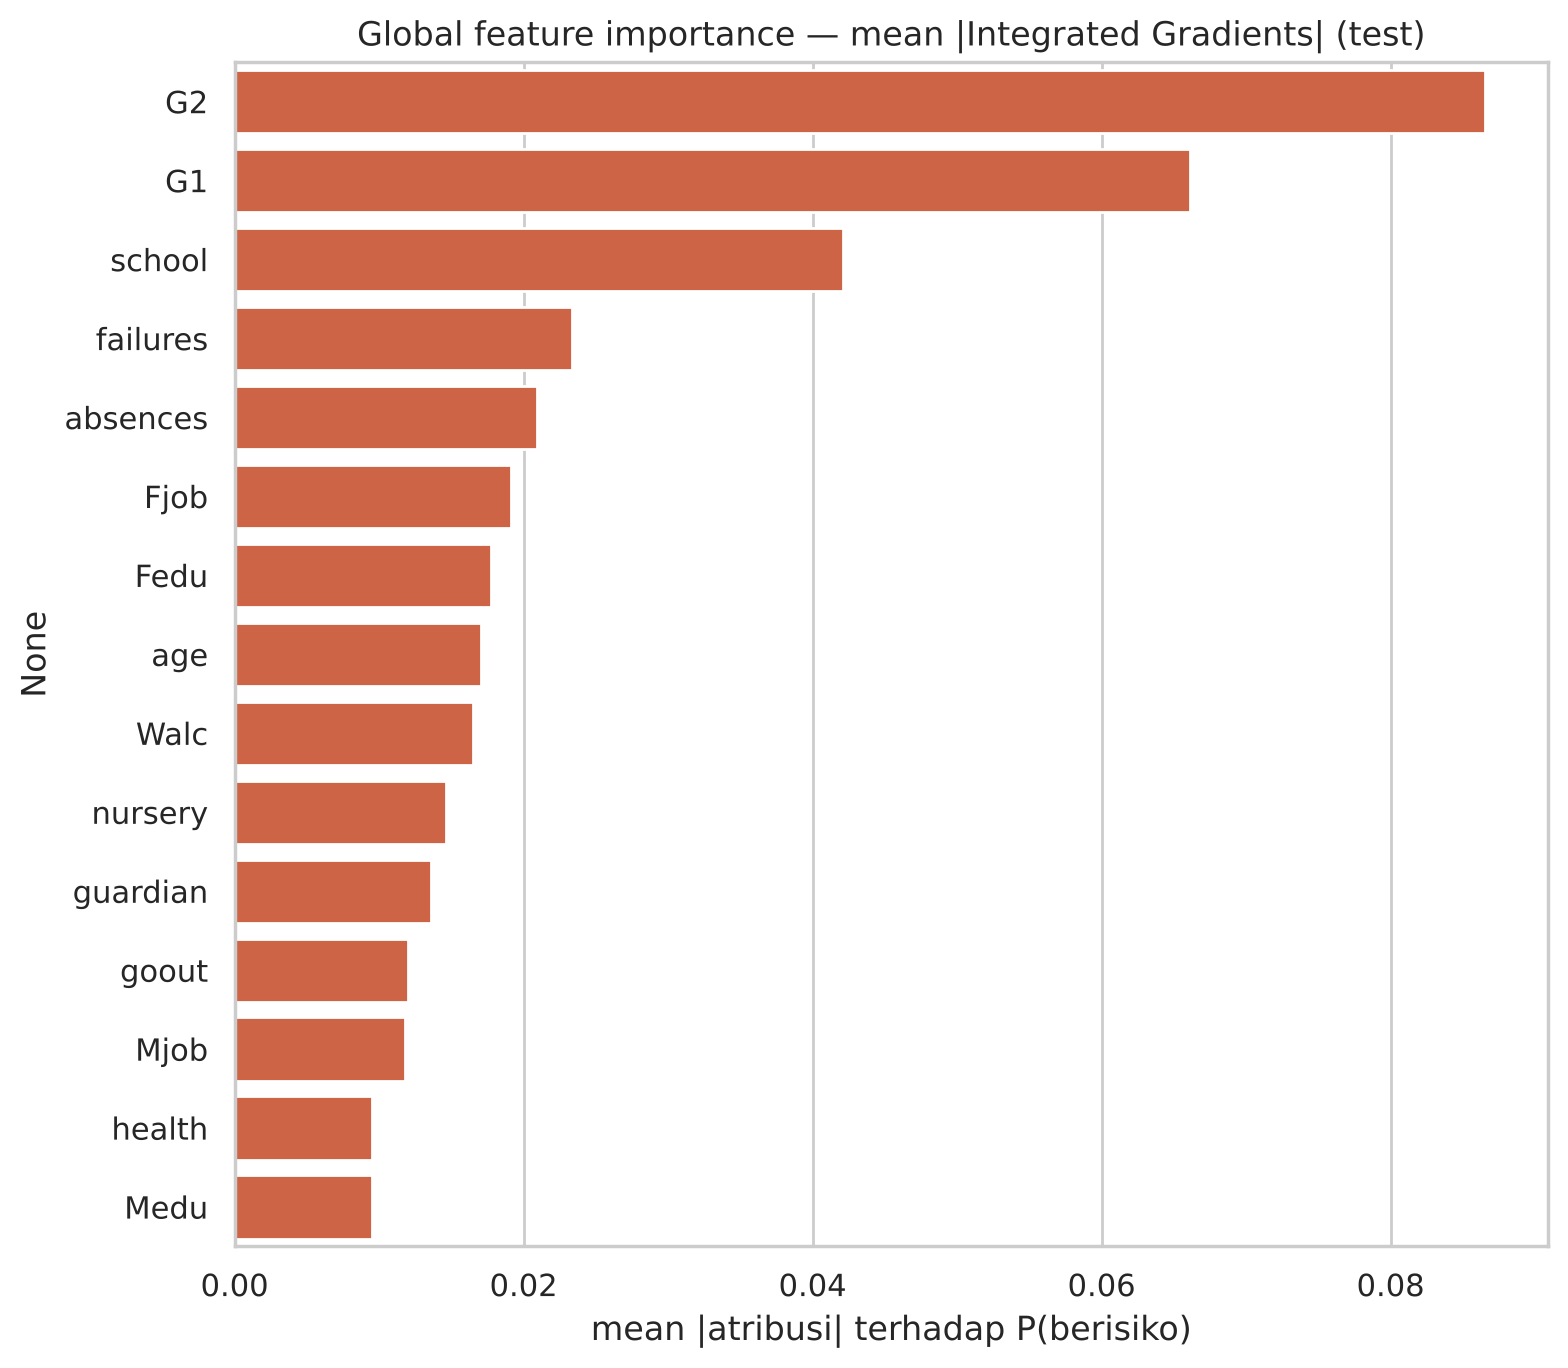

G2          0.0866
G1          0.0661
school      0.0421
failures    0.0233
absences    0.0209
Fjob        0.0192
Fedu        0.0177
age         0.0171
Walc        0.0165
nursery     0.0146
dtype: float32


In [37]:
glob_imp = IG_grp.abs().mean().sort_values(ascending=False)
plt.figure(figsize=(8, 7))
sns.barplot(x=glob_imp.values[:15], y=glob_imp.index[:15], color=C_RISK)
plt.title("Global feature importance — mean |Integrated Gradients| (test)"); plt.xlabel("mean |atribusi| terhadap P(berisiko)")
savefig("11_ig_global_importance")
print(glob_imp.head(10).round(4))

In [38]:
# Bukti dampak: deletion test — mengganti 3 fitur teratas (menurut IG) dengan baseline harus menurunkan
# keyakinan model jauh lebih besar dibanding mengganti 3 fitur acak.
def deletion_test(k=3, n_random=20, rng=np.random.default_rng(SEED)):
    d_ig, d_rand = [], []
    for i in range(len(Xte)):
        x = Xte[i]; p0 = p_test[i]
        top = IG_grp.iloc[i].abs().sort_values(ascending=False).index[:k]
        xm = x.copy()
        for g in top: xm[GROUP_IDX[g]] = BASELINE[GROUP_IDX[g]]
        d_ig.append(abs(p0 - model(xm[None], training=False).numpy()[0, 0]))
        rr = []
        for _ in range(n_random):
            xr = x.copy()
            for g in rng.choice(GROUP_NAMES, k, replace=False): xr[GROUP_IDX[g]] = BASELINE[GROUP_IDX[g]]
            rr.append(abs(p0 - model(xr[None], training=False).numpy()[0, 0]))
        d_rand.append(np.mean(rr))
    return float(np.mean(d_ig)), float(np.mean(d_rand))
DEL_IG, DEL_RAND = deletion_test()
print(f"Rata-rata |Δ probabilitas| ketika 3 fitur dihapus -> top-IG: {DEL_IG:.4f} | acak: {DEL_RAND:.4f} | rasio {DEL_IG/DEL_RAND:.1f}x")

Rata-rata |Δ probabilitas| ketika 3 fitur dihapus -> top-IG: 0.1464 | acak: 0.0275 | rasio 5.3x


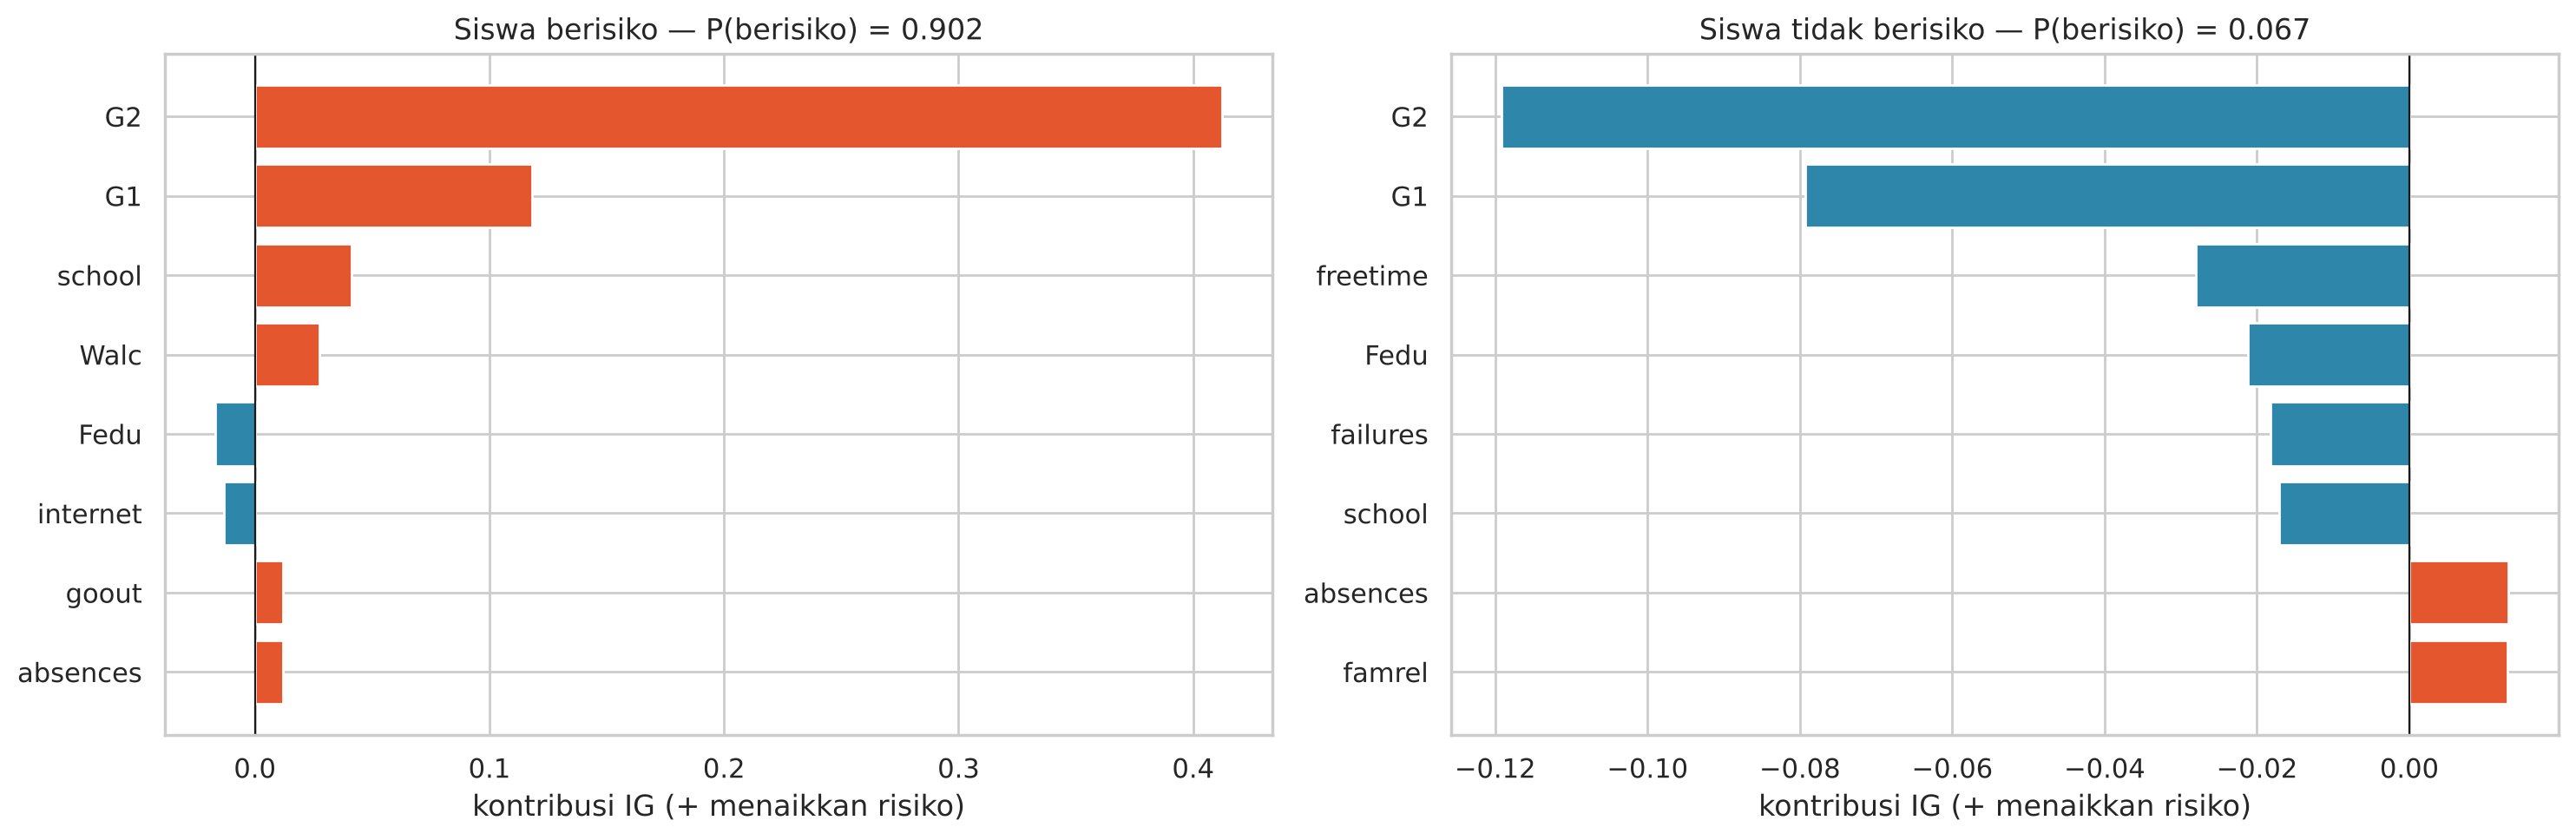

In [39]:
# Contoh penjelasan lokal: satu siswa berisiko dan satu siswa tidak berisiko dari data test
idx_risk = int(np.argmax(np.where(y_test == 1, p_test, -1))); idx_safe = int(np.argmin(np.where(y_test == 0, p_test, 2)))
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
for a, i, t in [(ax[0], idx_risk, "Siswa berisiko"), (ax[1], idx_safe, "Siswa tidak berisiko")]:
    s = IG_grp.iloc[i]; s = s.reindex(s.abs().sort_values(ascending=False).index[:8])[::-1]
    a.barh(s.index, s.values, color=[C_RISK if v > 0 else C_SAFE for v in s.values]); a.axvline(0, color="k", lw=.8)
    a.set_title(f"{t} — P(berisiko) = {p_test[i]:.3f}"); a.set_xlabel("kontribusi IG (+ menaikkan risiko)")
savefig("12_ig_penjelasan_lokal")

## 10. Analisis Risiko: Tingkat Risiko & Rekomendasi

In [40]:
RISK_LEVELS = [(0.30, "Rendah"), (0.50, "Sedang"), (1.01, "Tinggi")]
def risk_level(p):
    for th, nm in RISK_LEVELS:
        if p < th: return nm
lvl = pd.Series([risk_level(p) for p in p_test], name="tingkat")
risk_tab = pd.crosstab(lvl, pd.Series(y_test, name="aktual").map(LABELS)).reindex(["Rendah", "Sedang", "Tinggi"]).fillna(0).astype(int)
risk_tab["% berisiko aktual"] = (risk_tab.get("Berisiko", 0) / risk_tab.sum(1) * 100).round(1)
print(risk_tab)

aktual   Berisiko  Tidak Berisiko  % berisiko aktual
tingkat                                             
Rendah          0              69                0.0
Sedang          5              28               15.2
Tinggi         15              13               53.6


## 11. Simpan Model & Artefak

In [41]:
model.save("models/mlp_student_risk.keras")
joblib.dump(preprocessor, "models/preprocessor.joblib")

defaults = {c: (int(X_train[c].median()) if c in NUMERIC_COLS else X_train[c].mode()[0]) for c in FEATURES}
choices = {c: sorted(df[c].unique().tolist()) for c in BINARY_COLS + NOMINAL_COLS}
METADATA = {
    "features": FEATURES, "numeric": NUMERIC_COLS, "binary": BINARY_COLS, "nominal": NOMINAL_COLS,
    "feature_out": FEAT_OUT, "groups": GROUPS, "baseline": BASELINE.tolist(), "p_baseline": p_base,
    "threshold": THRESHOLD, "risk_levels": RISK_LEVELS, "pass_mark": PASS_MARK,
    "valid_ranges": {k: v for k, v in VALID_RANGES.items() if k in FEATURES},
    "defaults": defaults, "choices": choices, "config": {**BASE_CFG, "units": list(BASE_CFG["units"]), "focal_alpha": FOCAL_ALPHA},
}
json.dump(METADATA, open("models/metadata.json", "w"), indent=2, default=str)

def agg_to_dict(agg):
    return {s: {m: {"mean": round(float(agg.loc[s, (m, "mean")]), 4), "std": round(float(agg.loc[s, (m, "std")]), 4)}
                for m in ["val_f1", "val_pr_auc", "accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc", "epochs"]} for s in agg.index}
RESULTS = {
    "versions": VERSIONS, "eda": EDA_SUMMARY, "cleaning": CLEAN, "preprocessing_file": "results/preprocessing.json", "split": split_df.reset_index().to_dict("records"),
    "n_input": N_INPUT, "params": N_PARAMS, "architecture": ARCH_TABLE, "config": METADATA["config"],
    "class_weight": {str(k): round(v, 4) for k, v in CLASS_WEIGHT.items()},
    "epochs_run": EPOCHS_RUN, "best_epoch": BEST_EPOCH,
    "main_metrics": {s: {k: round(float(v), 4) for k, v in d.items()} for s, d in MAIN.items()},
    "confusion_matrix": {"tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)},
    "classification_report": classification_report(y_test, y_pred, target_names=[LABELS[0], LABELS[1]], output_dict=True),
    "scenario_loss": agg_to_dict(loss_agg), "scenario_arch": agg_to_dict(arch_agg), "scenario_features": agg_to_dict(feat_agg),
    "error_by_band": band.reset_index().astype(str).to_dict("records"),
    "fn_cases": err[err.jenis == "FN"][cols_show].astype(str).to_dict("records"),
    "fp_cases": err[err.jenis == "FP"][cols_show].sort_values("prob", ascending=False).astype(str).to_dict("records"),
    "overfit_gap": {k: round(float(v), 4) for k, v in GAP.items()},
    "ig": {"p_baseline": round(p_base, 4), "completeness_err": round(float(completeness.mean()), 6),
           "global_top": {k: round(float(v), 4) for k, v in glob_imp.head(12).items()},
           "deletion_top3": round(DEL_IG, 4), "deletion_random3": round(DEL_RAND, 4),
           "example_risk_p": round(float(p_test[idx_risk]), 4), "example_safe_p": round(float(p_test[idx_safe]), 4),
           "example_risk_top": {k: round(float(v), 4) for k, v in IG_grp.iloc[idx_risk].reindex(IG_grp.iloc[idx_risk].abs().sort_values(ascending=False).index[:5]).items()},
           "example_safe_top": {k: round(float(v), 4) for k, v in IG_grp.iloc[idx_safe].reindex(IG_grp.iloc[idx_safe].abs().sort_values(ascending=False).index[:5]).items()}},
    "risk_levels_table": risk_tab.reset_index().astype(str).to_dict("records"),
}
json.dump(RESULTS, open("results/metrics.json", "w"), indent=2, default=str)
print("Tersimpan:", os.listdir("models"), os.listdir("results"))

Tersimpan: ['preprocessor.joblib', 'metadata.json', 'mlp_student_risk.keras'] ['metrics.json', 'preprocessing.json', 'history_main.csv', 'eda_summary.json', 'scenario_runs.csv']


In [42]:
# Uji inferensi dari file (sama seperti yang dipakai aplikasi web)
_m2 = keras.models.load_model("models/mlp_student_risk.keras", compile=False)
_pp = joblib.load("models/preprocessor.joblib")
sample = X_test.iloc[[idx_risk]]
p_loaded = float(_m2.predict(_pp.transform(sample).astype("float32"), verbose=0)[0, 0])
print("P(berisiko) dari model tersimpan:", round(p_loaded, 4), "| sama dengan di memori:", np.isclose(p_loaded, p_test[idx_risk], atol=1e-5))

P(berisiko) dari model tersimpan: 0.9015 | sama dengan di memori: True


E0000 00:00:1793992065.792980     265 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


## 12. Ekspor Proyek (file .py untuk GitHub)

In [43]:
%%writefile app.py
"""Student Academic Risk Prediction — aplikasi web Gradio (model MLP).
Jalankan lokal: python app.py   |   Colab: import app; app.build_demo().launch(share=True)
"""
import os, json
import numpy as np
import pandas as pd
import joblib
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
import gradio as gr

BASE = os.path.dirname(os.path.abspath(__file__))
MODEL = keras.models.load_model(os.path.join(BASE, "models", "mlp_student_risk.keras"), compile=False)
PREP = joblib.load(os.path.join(BASE, "models", "preprocessor.joblib"))
META = json.load(open(os.path.join(BASE, "models", "metadata.json")))
METRICS = json.load(open(os.path.join(BASE, "results", "metrics.json")))
BASELINE = np.array(META["baseline"], dtype="float32")
GROUPS = META["groups"]
GROUP_IDX = {g: [i for i, x in enumerate(GROUPS) if x == g] for g in dict.fromkeys(GROUPS)}

LABEL_ID = {
    "school": "Sekolah", "sex": "Jenis kelamin", "age": "Usia", "address": "Tempat tinggal", "famsize": "Ukuran keluarga",
    "Pstatus": "Status orang tua", "Medu": "Pendidikan ibu (0-4)", "Fedu": "Pendidikan ayah (0-4)", "Mjob": "Pekerjaan ibu",
    "Fjob": "Pekerjaan ayah", "reason": "Alasan memilih sekolah", "guardian": "Wali", "traveltime": "Waktu tempuh (1-4)",
    "studytime": "Waktu belajar/minggu (1-4)", "failures": "Jumlah gagal kelas sebelumnya", "schoolsup": "Bimbingan sekolah",
    "famsup": "Dukungan belajar keluarga", "paid": "Les berbayar", "activities": "Ekstrakurikuler", "nursery": "Pernah PAUD",
    "higher": "Ingin kuliah", "internet": "Internet di rumah", "romantic": "Berpacaran", "famrel": "Hubungan keluarga (1-5)",
    "freetime": "Waktu luang (1-5)", "goout": "Frekuensi keluar rumah (1-5)", "Dalc": "Alkohol hari kerja (1-5)",
    "Walc": "Alkohol akhir pekan (1-5)", "health": "Kesehatan (1-5)", "absences": "Jumlah absen", "G1": "Nilai periode 1 (0-20)",
    "G2": "Nilai periode 2 (0-20)",
}
ADVICE = {
    "G2": "Nilai periode 2 rendah: jadwalkan remedial dan pendampingan intensif sebelum ujian akhir.",
    "G1": "Nilai periode 1 rendah: lakukan diagnosis materi yang tertinggal sejak awal semester.",
    "failures": "Riwayat gagal kelas: tetapkan wali/mentor akademik dan pantau kemajuan tiap bulan.",
    "absences": "Absensi tinggi: koordinasi dengan orang tua dan pantau kehadiran mingguan.",
    "studytime": "Waktu belajar kurang: susun jadwal belajar terstruktur atau kelompok belajar.",
    "higher": "Motivasi studi lanjut rendah: konseling karier untuk menumbuhkan tujuan akademik.",
    "Dalc": "Konsumsi alkohol hari kerja: rujuk ke konselor sekolah.",
    "Walc": "Konsumsi alkohol akhir pekan: edukasi dan konseling gaya hidup sehat.",
    "goout": "Sering keluar rumah: bantu manajemen waktu antara sosial dan belajar.",
    "schoolsup": "Sudah/perlu bimbingan sekolah: evaluasi efektivitas program bimbingan yang diikuti.",
    "school": "Faktor sekolah asal: bandingkan dukungan akademik antar sekolah.",
}

# rekomendasi hanya diberikan bila nilai fiturnya memang tergolong kurang baik
NEEDS = {"G2": lambda v: v < 12, "G1": lambda v: v < 12, "failures": lambda v: v >= 1, "absences": lambda v: v >= 8,
         "studytime": lambda v: v <= 1, "higher": lambda v: v == "no", "Dalc": lambda v: v >= 3, "Walc": lambda v: v >= 3,
         "goout": lambda v: v >= 4}

def risk_level(p):
    for th, nm in META["risk_levels"]:
        if p < th:
            return nm
    return META["risk_levels"][-1][1]

def integrated_gradients(x, steps=64):
    alphas = tf.reshape(tf.linspace(0.0, 1.0, steps + 1), (-1, 1))
    b = tf.constant(BASELINE[None, :]); x = tf.constant(x[None, :].astype("float32"))
    path = b + alphas * (x - b)
    with tf.GradientTape() as tape:
        tape.watch(path); pr = MODEL(path, training=False)[:, 0]
    g = tape.gradient(pr, path)
    attr = ((x - b)[0] * tf.reduce_mean((g[:-1] + g[1:]) / 2.0, axis=0)).numpy()
    return pd.Series({grp: float(attr[idx].sum()) for grp, idx in GROUP_IDX.items()})

def predict_frame(df):
    Xt = PREP.transform(df[META["features"]]).astype("float32")
    return MODEL.predict(Xt, verbose=0).ravel(), Xt

def explain_plot(contrib, p):
    top = contrib.reindex(contrib.abs().sort_values(ascending=False).index[:10])[::-1]
    fig, ax = plt.subplots(figsize=(7, 4.5))
    ax.barh([LABEL_ID.get(k, k) for k in top.index], top.values, color=["#E4572E" if v > 0 else "#2E86AB" for v in top.values])
    ax.axvline(0, color="k", lw=.8)
    ax.set_title(f"Faktor penentu (Integrated Gradients) — P(berisiko) = {p:.2f}")
    ax.set_xlabel("merah = menaikkan risiko, biru = menurunkan risiko")
    fig.tight_layout()
    return fig

def predict_one(*values):
    row = pd.DataFrame([dict(zip(META["features"], values))])
    for c in META["numeric"]:
        row[c] = pd.to_numeric(row[c])
    p, Xt = predict_frame(row); p = float(p[0])
    contrib = integrated_gradients(Xt[0])
    lvl = risk_level(p)
    up = contrib[contrib > 0].sort_values(ascending=False)
    vals = row.iloc[0]
    recs = [ADVICE[k] for k in up.index if k in ADVICE and NEEDS.get(k, lambda v: True)(vals[k])][:3] or ["Pertahankan pola belajar saat ini dan lakukan pemantauan rutin."]
    md = (f"### Tingkat risiko: **{lvl}**\n"
          f"Probabilitas tidak lulus (G3 < {META['pass_mark']}): **{p*100:.1f}%** — ambang keputusan {META['threshold']}\n\n"
          f"**Faktor yang paling menaikkan risiko:** " + (", ".join(LABEL_ID.get(k, k) for k in up.index[:3]) or "-") + "\n\n"
          "**Rekomendasi intervensi:**\n" + "\n".join(f"- {r}" for r in recs))
    return {"Berisiko": p, "Tidak Berisiko": 1 - p}, md, explain_plot(contrib, p)

def predict_batch(file):
    if file is None:
        return None, None, None
    df = pd.read_csv(file, sep=None, engine="python")
    df.columns = [c.strip().strip('"') for c in df.columns]
    missing = [c for c in META["features"] if c not in df.columns]
    if missing:
        raise gr.Error(f"Kolom tidak ditemukan: {missing}")
    for c in META["numeric"]:
        df[c] = pd.to_numeric(df[c], errors="coerce")
    p, _ = predict_frame(df)
    out = df.copy(); out["prob_berisiko"] = p.round(4); out["tingkat_risiko"] = [risk_level(v) for v in p]
    out = out.sort_values("prob_berisiko", ascending=False)
    path = os.path.join(BASE, "hasil_prediksi.csv"); out.to_csv(path, index=False)
    fig, ax = plt.subplots(figsize=(6, 3.5))
    vc = out["tingkat_risiko"].value_counts().reindex(["Rendah", "Sedang", "Tinggi"]).fillna(0)
    ax.bar(vc.index, vc.values, color=["#2E86AB", "#F4A261", "#E4572E"]); ax.set_title(f"Sebaran tingkat risiko ({len(out)} siswa)")
    fig.tight_layout()
    show = ["prob_berisiko", "tingkat_risiko"] + [c for c in ["school", "sex", "age", "failures", "absences", "G1", "G2"] if c in out]
    return out[show].head(100), fig, path

def build_inputs():
    comps = {}
    rng, dflt, ch = META["valid_ranges"], META["defaults"], META["choices"]
    sections = [("Demografi", ["school", "sex", "age", "address"]),
                ("Keluarga", ["famsize", "Pstatus", "Medu", "Fedu", "Mjob", "Fjob", "guardian", "famrel", "famsup"]),
                ("Sekolah & Belajar", ["reason", "traveltime", "studytime", "failures", "schoolsup", "paid", "activities", "nursery", "higher", "internet", "absences"]),
                ("Sosial & Gaya Hidup", ["romantic", "freetime", "goout", "Dalc", "Walc", "health"])]
    with gr.Row():
        comps["G1"] = gr.Slider(0, 20, value=dflt["G1"], step=1, label=LABEL_ID["G1"])
        comps["G2"] = gr.Slider(0, 20, value=dflt["G2"], step=1, label=LABEL_ID["G2"])
    for title, cols in sections:
        with gr.Accordion(title, open=(title == "Sekolah & Belajar")):
            with gr.Row():
                for c in cols:
                    if c in META["numeric"]:
                        lo, hi = rng[c]
                        comps[c] = gr.Slider(lo, hi, value=dflt[c], step=1, label=LABEL_ID.get(c, c), min_width=180)
                    else:
                        comps[c] = gr.Dropdown(ch[c], value=dflt[c], label=LABEL_ID.get(c, c), min_width=180)
    return [comps[c] for c in META["features"]]

def build_demo():
    m = METRICS["main_metrics"]["test"]
    with gr.Blocks(title="Student Academic Risk Prediction") as demo:
        gr.Markdown("# 🎓 Student Academic Risk Prediction\nSistem prediksi & analisis risiko akademik siswa berbasis **Multilayer Perceptron** "
                    "(dataset Student Performance — mata pelajaran Bahasa Portugis). Siswa dikategorikan *berisiko* bila diprediksi G3 < 10.")
        with gr.Tab("Prediksi Individu"):
            with gr.Row():
                with gr.Column(scale=3):
                    inputs = build_inputs()
                    btn = gr.Button("Analisis Risiko", variant="primary")
                with gr.Column(scale=2):
                    out_label = gr.Label(label="Probabilitas", num_top_classes=2)
                    out_md = gr.Markdown()
                    out_plot = gr.Plot(label="Penjelasan model")
            btn.click(predict_one, inputs, [out_label, out_md, out_plot])
        with gr.Tab("Prediksi Batch (CSV)"):
            gr.Markdown("Unggah CSV dengan kolom yang sama seperti dataset (G3 tidak wajib). Hasil diurutkan dari risiko tertinggi.")
            f_in = gr.File(label="File CSV", file_types=[".csv"], type="filepath")
            b_btn = gr.Button("Prediksi", variant="primary")
            b_tab = gr.Dataframe(label="Hasil (100 teratas)")
            b_plot = gr.Plot(); b_file = gr.File(label="Unduh hasil lengkap")
            b_btn.click(predict_batch, f_in, [b_tab, b_plot, b_file])
        with gr.Tab("Tentang Model"):
            gr.Markdown(f"""**Arsitektur:** MLP {'-'.join(map(str, META['config']['units']))} + BatchNorm + ReLU + Dropout {META['config']['dropout']}, output sigmoid
**Loss:** Binary Focal Crossentropy (alpha={META['config']['focal_alpha']}, gamma={META['config']['gamma']}) · **Optimizer:** Adam lr={META['config']['lr']}
**Hasil data testing:** Accuracy {m['accuracy']:.4f} · Precision {m['precision']:.4f} · Recall {m['recall']:.4f} · F1 {m['f1']:.4f} · ROC-AUC {m['roc_auc']:.4f}
**Explainability:** Integrated Gradients (baseline = rata-rata data training)
**Tingkat risiko:** Rendah < 0.30 ≤ Sedang < 0.50 ≤ Tinggi""")
    return demo

if __name__ == "__main__":
    build_demo().launch(server_name="0.0.0.0", server_port=int(os.environ.get("PORT", 7860)))

Overwriting app.py


In [44]:
%%writefile train.py
"""Melatih ulang model utama (MLP 64-32, lr 1e-2, focal loss) dari CSV — versi skrip dari notebook.
Pemakaian: python train.py   (membaca data/student-por.csv, menulis models/ dan results/train_metrics.json)
"""
import os, json, random
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
import numpy as np, pandas as pd, joblib, tensorflow as tf
from tensorflow import keras
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, average_precision_score

SEED, PASS_MARK = 42, 10
BINARY_COLS = ["school", "sex", "address", "famsize", "Pstatus", "schoolsup", "famsup", "paid", "activities", "nursery", "higher", "internet", "romantic"]
NOMINAL_COLS = ["Mjob", "Fjob", "reason", "guardian"]
NUMERIC_COLS = ["age", "Medu", "Fedu", "traveltime", "studytime", "failures", "famrel", "freetime", "goout", "Dalc", "Walc", "health", "absences", "G1", "G2"]
FEATURES = NUMERIC_COLS + BINARY_COLS + NOMINAL_COLS
CFG = dict(units=(64, 32), dropout=0.3, l2=1e-3, lr=1e-2, batch_size=32, epochs=200, gamma=2.0, patience=25)

def set_seed(s):
    os.environ["PYTHONHASHSEED"] = str(s); random.seed(s); np.random.seed(s); keras.utils.set_random_seed(s)

def main(path="data/student-por.csv"):
    tf.config.experimental.enable_op_determinism()
    df = pd.read_csv(path, sep=None, engine="python"); df.columns = [c.strip().strip('"') for c in df.columns]
    for c in ["G1", "G2", "G3"]: df[c] = pd.to_numeric(df[c], errors="coerce")
    df = df.drop_duplicates().dropna(subset=FEATURES + ["G3"]).reset_index(drop=True)
    df["at_risk"] = (df["G3"] < PASS_MARK).astype(int)
    X, y = df[FEATURES], df["at_risk"].values
    X_tmp, X_te, y_tmp, y_te = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
    X_tr, X_va, y_tr, y_va = train_test_split(X_tmp, y_tmp, test_size=0.25, stratify=y_tmp, random_state=SEED)
    prep = ColumnTransformer([("num", StandardScaler(), NUMERIC_COLS),
                              ("bin", OneHotEncoder(drop="if_binary", handle_unknown="ignore"), BINARY_COLS),
                              ("nom", OneHotEncoder(handle_unknown="ignore"), NOMINAL_COLS)], sparse_threshold=0)
    A, B, C = (prep.fit_transform(X_tr).astype("float32"), prep.transform(X_va).astype("float32"), prep.transform(X_te).astype("float32"))
    alpha = round(1 - float(y_tr.mean()), 4)
    set_seed(SEED)
    inp = keras.Input(shape=(A.shape[1],), name="fitur_siswa"); x = inp
    for i, u in enumerate(CFG["units"], 1):
        x = keras.layers.Dense(u, kernel_regularizer=keras.regularizers.l2(CFG["l2"]), name=f"dense_{i}")(x)
        x = keras.layers.BatchNormalization(name=f"batchnorm_{i}")(x)
        x = keras.layers.Activation("relu", name=f"relu_{i}")(x)
        x = keras.layers.Dropout(CFG["dropout"], name=f"dropout_{i}")(x)
    model = keras.Model(inp, keras.layers.Dense(1, activation="sigmoid", name="prob_berisiko")(x), name="student_risk_mlp")
    model.compile(optimizer=keras.optimizers.Adam(CFG["lr"]),
                  loss=keras.losses.BinaryFocalCrossentropy(apply_class_balancing=True, alpha=alpha, gamma=CFG["gamma"]),
                  metrics=[keras.metrics.AUC(name="auc"), keras.metrics.BinaryAccuracy(name="accuracy"),
                           keras.metrics.Recall(name="recall"), keras.metrics.Precision(name="precision")])
    model.fit(A, y_tr, validation_data=(B, y_va), epochs=CFG["epochs"], batch_size=CFG["batch_size"], verbose=2, shuffle=True,
              callbacks=[keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=CFG["patience"], restore_best_weights=True),
                         keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=10, min_lr=1e-5)])
    p = model.predict(C, verbose=0).ravel(); yp = (p >= 0.5).astype(int)
    res = {"accuracy": accuracy_score(y_te, yp), "precision": precision_score(y_te, yp), "recall": recall_score(y_te, yp),
           "f1": f1_score(y_te, yp), "roc_auc": roc_auc_score(y_te, p), "pr_auc": average_precision_score(y_te, p)}
    res = {k: round(float(v), 4) for k, v in res.items()}
    os.makedirs("models", exist_ok=True); os.makedirs("results", exist_ok=True)
    model.save("models/mlp_student_risk.keras"); joblib.dump(prep, "models/preprocessor.joblib")
    json.dump(res, open("results/train_metrics.json", "w"), indent=2)
    print("Test metrics:", res)

if __name__ == "__main__":
    main()

Overwriting train.py


In [45]:
%%writefile requirements.txt
tensorflow>=2.16
numpy
pandas
scikit-learn
joblib
matplotlib
seaborn
gradio>=4.0

Overwriting requirements.txt


In [46]:
_m = RESULTS["main_metrics"]["test"]
readme = f"""# Student Academic Risk Prediction
Sistem prediksi dan analisis risiko akademik siswa menggunakan **Multilayer Perceptron (Deep Neural Network)**.

- Dataset: [Student Performance Data Set (Kaggle)](https://www.kaggle.com/datasets/larsen0966/student-performance-data-set) — `student-por.csv`, {EDA_SUMMARY['n_rows']} siswa, 33 atribut (asal: UCI, Cortez & Silva, 2008)
- Target: `at_risk = 1` jika nilai akhir G3 < 10 ({EDA_SUMMARY['pct_at_risk']}% data)
- Model: MLP 64-32 (BatchNorm, ReLU, Dropout 0.3, L2) + **Focal Loss** · Explainability: **Integrated Gradients**
- Hasil test: Accuracy {_m['accuracy']:.4f} · Precision {_m['precision']:.4f} · Recall {_m['recall']:.4f} · F1 {_m['f1']:.4f} · ROC-AUC {_m['roc_auc']:.4f}

## Struktur
```
notebook/   Student_Academic_Risk_MLP.ipynb   (EDA → preprocessing → training → evaluasi)
app.py      aplikasi web Gradio (prediksi individu, batch CSV, penjelasan IG)
train.py    skrip pelatihan ulang model utama
models/     mlp_student_risk.keras, preprocessor.joblib, metadata.json
results/    metrics.json, eda_summary.json, scenario_runs.csv, history_main.csv
figures/    grafik EDA & evaluasi
data/       student-por.csv
```

## Menjalankan
```bash
pip install -r requirements.txt
python app.py          # buka http://localhost:7860
python train.py        # (opsional) latih ulang model
```
Deploy ke Hugging Face Spaces: buat Space bertipe Gradio, unggah seluruh isi repo (app.py di root).
"""
open("README.md", "w").write(readme)
open(".gitignore", "w").write("__pycache__/\n*.pyc\n.ipynb_checkpoints/\nhasil_prediksi.csv\n.gradio/\n")
print(readme)

# Student Academic Risk Prediction
Sistem prediksi dan analisis risiko akademik siswa menggunakan **Multilayer Perceptron (Deep Neural Network)**.

- Dataset: [Student Performance Data Set (Kaggle)](https://www.kaggle.com/datasets/larsen0966/student-performance-data-set) — `student-por.csv`, 649 siswa, 33 atribut (asal: UCI, Cortez & Silva, 2008)
- Target: `at_risk = 1` jika nilai akhir G3 < 10 (15.41% data)
- Model: MLP 64-32 (BatchNorm, ReLU, Dropout 0.3, L2) + **Focal Loss** · Explainability: **Integrated Gradients**
- Hasil test: Accuracy 0.8615 · Precision 0.5357 · Recall 0.7500 · F1 0.6250 · ROC-AUC 0.9182

## Struktur
```
notebook/   Student_Academic_Risk_MLP.ipynb   (EDA → preprocessing → training → evaluasi)
app.py      aplikasi web Gradio (prediksi individu, batch CSV, penjelasan IG)
train.py    skrip pelatihan ulang model utama
models/     mlp_student_risk.keras, preprocessor.joblib, metadata.json
results/    metrics.json, eda_summary.json, scenario_runs.csv, history_main.cs

In [47]:
# Zip seluruh proyek untuk di-push ke GitHub (salin juga notebook ini ke folder notebook/ jika ada)
os.makedirs("notebook", exist_ok=True)
for nb in glob.glob("/content/*.ipynb") + glob.glob("../*.ipynb"):
    shutil.copy(nb, "notebook/Student_Academic_Risk_MLP.ipynb")
ZIP_NAME = f"../{PROJECT_DIR}.zip"
with zipfile.ZipFile(ZIP_NAME, "w", zipfile.ZIP_DEFLATED) as z:
    for root, _, files in os.walk("."):
        if any(s in root for s in ["__pycache__", ".ipynb_checkpoints", ".gradio"]): continue
        for f in files:
            if f == "hasil_prediksi.csv": continue
            p = os.path.join(root, f); z.write(p, os.path.join(PROJECT_DIR, os.path.relpath(p, ".")))
print("ZIP:", os.path.abspath(ZIP_NAME), f"({os.path.getsize(ZIP_NAME)/1024:.0f} KB)")
for n in sorted(zipfile.ZipFile(ZIP_NAME).namelist()): print("  ", n)
try:
    from google.colab import files; files.download(ZIP_NAME)
except Exception:
    pass

ZIP: /home/claude/run/student-academic-risk.zip (3682 KB)
   student-academic-risk/.gitignore
   student-academic-risk/README.md
   student-academic-risk/app.py
   student-academic-risk/data/student-por.csv
   student-academic-risk/figures/01_distribusi_label.png
   student-academic-risk/figures/02_histogram_fitur_numerik.png
   student-academic-risk/figures/03_korelasi_fitur.png
   student-academic-risk/figures/04_risk_rate_kategorikal.png
   student-academic-risk/figures/05_hubungan_nilai_failures_absences.png
   student-academic-risk/figures/06_arsitektur_mlp.png
   student-academic-risk/figures/07_kurva_training.png
   student-academic-risk/figures/08_confusion_roc_pr.png
   student-academic-risk/figures/09_perbandingan_skenario.png
   student-academic-risk/figures/10_distribusi_probabilitas.png
   student-academic-risk/figures/11_ig_global_importance.png
   student-academic-risk/figures/12_ig_penjelasan_lokal.png
   student-academic-risk/figures/13_aplikasi_web.png
   student-acad

## 13. Jalankan Aplikasi Web (Gradio)

In [48]:
import importlib, app
importlib.reload(app)
demo = app.build_demo()
# uji fungsi prediksi sebelum launch
_lbl, _md, _fig = app.predict_one(*[X_test.iloc[idx_risk][c] for c in FEATURES]); plt.close(_fig)
print(_lbl); print(_md)
if os.environ.get("SKIP_APP_LAUNCH") != "1":
    demo.launch(share=True, debug=False)   # link publik *.gradio.live muncul di bawah

{'Berisiko': 0.9015096426010132, 'Tidak Berisiko': 0.09849035739898682}
### Tingkat risiko: **Tinggi**
Probabilitas tidak lulus (G3 < 10): **90.2%** — ambang keputusan 0.5

**Faktor yang paling menaikkan risiko:** Nilai periode 2 (0-20), Nilai periode 1 (0-20), Sekolah

**Rekomendasi intervensi:**
- Nilai periode 2 rendah: jadwalkan remedial dan pendampingan intensif sebelum ujian akhir.
- Nilai periode 1 rendah: lakukan diagnosis materi yang tertinggal sejak awal semester.
- Faktor sekolah asal: bandingkan dukungan akademik antar sekolah.
